In [1]:
import numpy as np
import h5py
import os
# import sys

# from matplotlib import pyplot as plt
# from tqdm import tqdm

# import torch
import sparse

In [2]:
import numba

@numba.njit()
def sparse_to_sparse(coords, values, num_prongs, num_features, shape_scale):
    DIMS = 4
    max_items = values.shape[0] + num_prongs
    
    output_coordinates = np.zeros((max_items, DIMS - 1), dtype=np.int64)
    output_values = np.zeros((max_items, num_features), dtype=np.float32)
    
    index_mapping = dict()
    num_unique_indices = 0

    for i in range(values.shape[0]): 
        v = values[i]
        if v == 0:
            continue

        b = coords[i, 0]
        c = coords[i, 1]
        y = coords[i, 2]
        x = coords[i, 3]
        
        if num_features == 3 and c == 1:
            y = 399 - y 

        flat_index = shape_scale[0] * b + shape_scale[1] * y + shape_scale[2] * x

        if flat_index not in index_mapping:
            output_index = num_unique_indices
            index_mapping[flat_index] = num_unique_indices
            num_unique_indices += 1
        else:
            output_index = index_mapping[flat_index]

        output_coordinates[output_index][0] = b
        output_coordinates[output_index][1] = y
        output_coordinates[output_index][2] = x

        output_values[output_index][c] = v

    non_zero_planes = set(output_coordinates[:num_unique_indices, 0])
    all_planes = set(np.arange(num_prongs, dtype=np.int64))
    missing_planes = all_planes.difference(non_zero_planes)

    for i in missing_planes:
        output_coordinates[num_unique_indices, 0] = i
        num_unique_indices += 1

    output_coordinates = output_coordinates[:num_unique_indices]
    output_values = output_values[:num_unique_indices]

    sorting_indices = np.argsort((output_coordinates * shape_scale).sum(1))
    output_coordinates = np.ascontiguousarray(output_coordinates[sorting_indices])
    output_values = np.ascontiguousarray(output_values[sorting_indices])
    
    return output_coordinates, output_values

def compress_first_index(indices, values, shape):
    assert np.all(np.diff(indices[:, 0]) >= 0)

    starts = np.searchsorted(indices[:, 0], np.arange(shape[0]))
    ends = np.concatenate((starts[1:], [indices.shape[0]]))

    return np.stack([starts, ends]).T

In [3]:
RENAME_PRONG_TARGET = False
ENERGY_LIMIT = None

# PATH = "/baldig/physicsprojects2/dune_prong_reco/data/data/dune/cut_data/preprocessed_data_dune_vertices_train.h5"
# OUTPUT = "training_filter"

# PATH = "/baldig/physicsprojects2/dune_prong_reco/data/data/dune/cut_data/preprocessed_data_dune_vertices_test.h5"
# OUTPUT = "testing_filter"

PATH = "./output/preprocessed_pixel_maps_test.h5"
OUTPUT = "output/postprocessed_pixel_maps_test.h5"

In [4]:
file = h5py.File(PATH, 'r')

num_events, num_prongs, *_ = file["png_cvnmap_shape"][:]

data = file["input_png3d"][:] if "input_png3d" in file else np.zeros((num_events, 24, num_prongs), dtype=np.float32)
mask = png_cvnmap_pad_mask = file['input_png3d_pad_mask'][:] if "input_png3d_pad_mask" in file else np.zeros((num_events, num_prongs), dtype=bool)
extra = file["input_slice"][:] if "input_slice" in file else np.zeros(num_events, dtype=np.float32)

# try:
#     nu_energy = file["mc.nuEnergy"][:]
#     lep_energy = file["mc.LepEnergy"][:]
# except KeyError:
#     pass

target = file["mc.inter"][:]
prong_targets = file["mc.png_label_split_photons"][:]

data = data.astype(np.float32)
data = data.transpose((0, 2, 1))
data = np.ascontiguousarray(data)

extra = extra.reshape(data.shape[0], -1).astype(np.float32)

unique_targets = np.unique(target)
target_map = {key: value for key, value in map(reversed, enumerate(unique_targets))}
target = np.fromiter((target_map[t] for t in target), dtype=np.int64, count=len(target))

# current_target = np.zeros_like(target)
# current_target[(target > 3) & (target <= 7)] = 1
# current_target[target == 8] = 2
# current_target[target == 9] = 3

if RENAME_PRONG_TARGET:
    prong_targets[prong_targets == 9] = 8
    
if not mask.any():
    mask = prong_targets >= 0

In [5]:
png_cvnmap_index = file["png_cvnmap_index"][:]
png_cvnmap_value = file["png_cvnmap_value"][:]
png_cvnmap_shape = file["png_cvnmap_shape"][:]

In [6]:
png_cvnmap_index[:,0]-=png_cvnmap_index[0][0]

In [7]:
cvnmap_index = file["cvnmap_index"][:]
cvnmap_value = file["cvnmap_value"][:]
cvnmap_shape = file["cvnmap_shape"][:]

In [8]:
cvnmap_index[:,0]-=cvnmap_index[0][0]

In [9]:
extra_index = np.zeros(cvnmap_index.shape[0], dtype=cvnmap_index.dtype)
cvnmap_index = np.insert(cvnmap_index, 1, extra_index, axis=1)
cvnmap_shape = np.insert(cvnmap_shape, 1, 1)

In [10]:
if RENAME_PRONG_TARGET:
    cvnmap_index = np.ascontiguousarray(cvnmap_index.T)
    cvnmap = sparse.COO(cvnmap_index, cvnmap_value, tuple(map(int, cvnmap_shape)))
    del cvnmap_index, cvnmap_value
    cvnmap = cvnmap.reshape((*cvnmap.shape[:2], 2, 100, 80)) 

    cvnmap_value = cvnmap.data
    cvnmap_index = np.ascontiguousarray(cvnmap.coords.T)
    cvnmap_shape = np.array(cvnmap.shape)
    del cvnmap

In [11]:
if RENAME_PRONG_TARGET:
    png_cvnmap_index = np.ascontiguousarray(png_cvnmap_index.T)
    png_cvnmap = sparse.COO(png_cvnmap_index, png_cvnmap_value, tuple(map(int, png_cvnmap_shape)))
    png_cvnmap = png_cvnmap.reshape((*png_cvnmap.shape[:2], 2, 100, 80))
    del png_cvnmap_index, png_cvnmap_value

    png_cvnmap_value = png_cvnmap.data
    png_cvnmap_index = np.ascontiguousarray(png_cvnmap.coords.T)
    png_cvnmap_shape = np.array(png_cvnmap.shape)
    del png_cvnmap

In [12]:
if ENERGY_LIMIT:
    energy_mask = extra.ravel() < ENERGY_LIMIT
    
    cvnmap = cvnmap[energy_mask]
    png_cvnmap = png_cvnmap[energy_mask]
    
    extra = extra[energy_mask]
    data = data[energy_mask]
    mask = mask[energy_mask]

    target = target[energy_mask]
    prong_targets = prong_targets[energy_mask]

    cvnmap_value = cvnmap.data
    cvnmap_index = np.ascontiguousarray(cvnmap.coords.T)
    cvnmap_shape = np.array(cvnmap.shape)

    png_cvnmap_value = png_cvnmap.data
    png_cvnmap_index = np.ascontiguousarray(png_cvnmap.coords.T)
    png_cvnmap_shape = np.array(png_cvnmap.shape)

In [13]:
if os.path.exists(PATH.replace(".h5", ".select.npy")):
    select_mask = np.load(PATH.replace(".h5", ".select.npy")) > 0.5
    select_mask = np.append(select_mask, [False])
    
    png_cvnmap_index = np.ascontiguousarray(png_cvnmap_index.T)
    cvnmap_index = np.ascontiguousarray(cvnmap_index.T)

    png_cvnmap = sparse.COO(png_cvnmap_index, png_cvnmap_value, tuple(map(int, png_cvnmap_shape)))
    cvnmap = sparse.COO(cvnmap_index, cvnmap_value, tuple(map(int, cvnmap_shape)))
    
    cvnmap = cvnmap[select_mask]
    png_cvnmap = png_cvnmap[select_mask]
    
    extra = extra[select_mask]
    data = data[select_mask]
    mask = mask[select_mask]
    
    target = target[select_mask]
    prong_targets = prong_targets[select_mask]
    
    cvnmap_value = cvnmap.data
    cvnmap_index = np.ascontiguousarray(cvnmap.coords.T)
    cvnmap_shape = np.array(cvnmap.shape)

    png_cvnmap_value = png_cvnmap.data
    png_cvnmap_index = np.ascontiguousarray(png_cvnmap.coords.T)
    png_cvnmap_shape = np.array(png_cvnmap.shape)

In [14]:
event_compressed_index = compress_first_index(cvnmap_index, cvnmap_value, cvnmap_shape)

In [15]:
prong_compressed_index = compress_first_index(png_cvnmap_index, png_cvnmap_value, png_cvnmap_shape)

In [16]:
image_size = cvnmap_shape[-2:]
shape_scale = np.ascontiguousarray(np.cumprod((*cvnmap_shape[-2:], 1)[::-1])[::-1])

In [17]:
image_size = png_cvnmap_shape[-2:]
shape_scale = np.ascontiguousarray(np.cumprod((*png_cvnmap_shape[-2:], 1)[::-1])[::-1])

In [18]:
from joblib import Parallel, delayed

In [19]:
def extract_event(i):
    lower, upper = event_compressed_index[i]
    num_prongs = 1
    num_features = cvnmap_shape[2]

    event_coordinates = cvnmap_index[lower:upper, 1:]
    event_values = cvnmap_value[lower:upper]
    return sparse_to_sparse(event_coordinates, event_values, num_prongs, num_features, shape_scale)

In [20]:
event_results = Parallel(n_jobs=32, verbose=1)(delayed(extract_event)(i) for i in range(len(event_compressed_index)))
all_event_coordinates = [result[0] for result in event_results]
all_event_values = [result[1] for result in event_results]

[Parallel(n_jobs=32)]: Using backend LokyBackend with 32 concurrent workers.
[Parallel(n_jobs=32)]: Done  94 out of  94 | elapsed:    5.2s finished


In [21]:
del cvnmap_value, cvnmap_index, event_results

In [22]:
event_lengths = np.array([0] + list(map(len, all_event_coordinates)))
event_compressed_index = np.stack((np.cumsum(event_lengths)[:-1], np.cumsum(event_lengths)[1:]), axis=1)

all_event_values = np.concatenate(all_event_values)
all_event_coordinates = np.concatenate(all_event_coordinates)

In [23]:
del event_lengths

In [24]:
def extract_prong(i):
    lower, upper = prong_compressed_index[i]
    
    num_prongs = max(mask[i].sum(), 1)
    num_features = png_cvnmap_shape[2]
    
    prong_coordinates = png_cvnmap_index[lower:upper, 1:]
    prong_values = png_cvnmap_value[lower:upper]
    return sparse_to_sparse(prong_coordinates, prong_values, num_prongs, num_features, shape_scale)

In [25]:
prong_results = Parallel(n_jobs=32, verbose=1)(delayed(extract_prong)(i) for i in range(len(prong_compressed_index)))
all_prong_coordinates = [result[0] for result in prong_results]
all_prong_values = [result[1] for result in prong_results]

[Parallel(n_jobs=32)]: Using backend LokyBackend with 32 concurrent workers.
[Parallel(n_jobs=32)]: Done  94 out of  94 | elapsed:    0.1s finished


In [26]:
del png_cvnmap_value, png_cvnmap_index, prong_results

In [27]:
prong_lengths = np.array([0] + list(map(len, all_prong_coordinates)))
prong_compressed_index = np.stack((np.cumsum(prong_lengths)[:-1], np.cumsum(prong_lengths)[1:]), axis=1)

all_prong_values = np.concatenate(all_prong_values)
all_prong_coordinates = np.concatenate(all_prong_coordinates)

In [28]:
del prong_lengths

In [29]:
all_event_coordinates = all_event_coordinates.astype(np.int32)

In [30]:
all_prong_coordinates = all_prong_coordinates.astype(np.int32)

In [31]:
num_events, max_prongs, *full_pixels_shape = png_cvnmap_shape

In [32]:
OUTPUT_FILE = f"./{OUTPUT}"
if ENERGY_LIMIT:
    OUTPUT_FILE = f"./data/nova_alt/{OUTPUT}_prong_pixels_minkowski_sparse_{ENERGY_LIMIT}_gev.h5"
    
print(OUTPUT_FILE)

./output/postprocessed_pixel_maps_test.h5


In [33]:
with h5py.File(OUTPUT_FILE, 'w') as output_file:
    output_file.create_dataset("features", data=data)
    output_file.create_dataset("extra", data=extra)

In [34]:
with h5py.File(OUTPUT_FILE, 'a') as output_file:
    output_file.create_dataset("event_target", data=target)
    output_file.create_dataset("event_pixels_coordinates", data=all_event_coordinates)
    output_file.create_dataset("event_pixels_values", data=all_event_values)
    output_file.create_dataset("event_pixels_shape", data=cvnmap_shape[1:])
    output_file.create_dataset("event_compressed_index", data=event_compressed_index)

In [35]:
del all_event_coordinates,all_event_values,event_compressed_index

In [36]:
with h5py.File(OUTPUT_FILE, 'a') as output_file:
    output_file.create_dataset("prong_target", data=prong_targets)
    output_file.create_dataset("prong_mask", data=mask)
    
    output_file.create_dataset("prong_pixels_coordinates", data=all_prong_coordinates)
    output_file.create_dataset("prong_pixels_values", data=all_prong_values)
    output_file.create_dataset("prong_pixels_shape", data=png_cvnmap_shape[1:])
    output_file.create_dataset("prong_compressed_index", data=prong_compressed_index)

    output_file.create_dataset("full_pixels_shape", data=np.array(full_pixels_shape))

In [37]:
del all_prong_coordinates,all_prong_values,prong_compressed_index

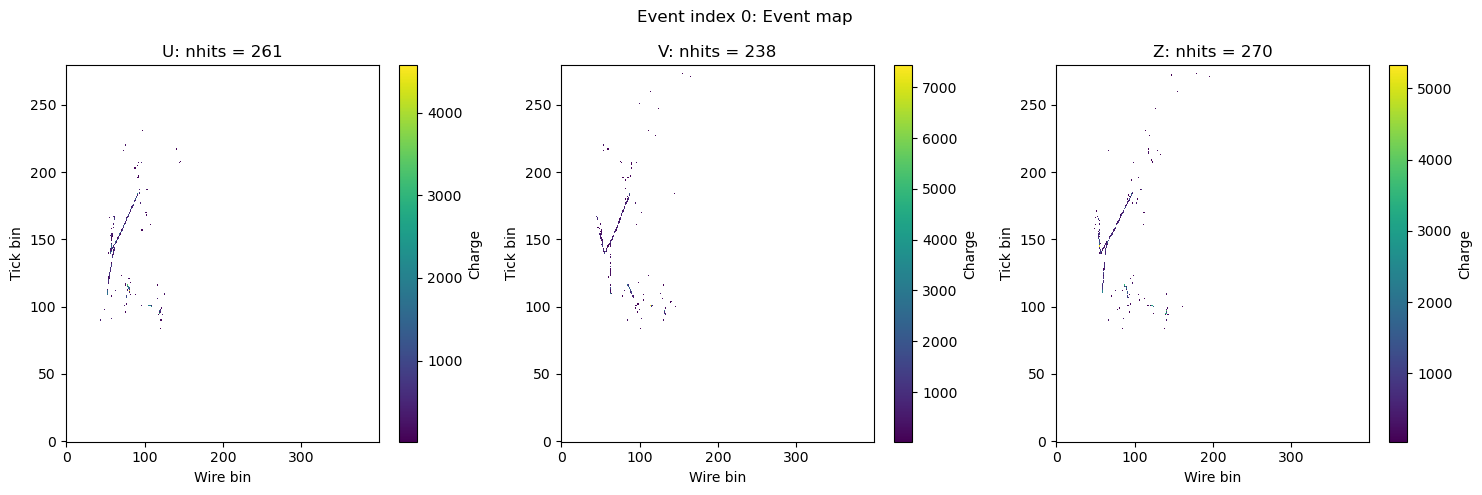

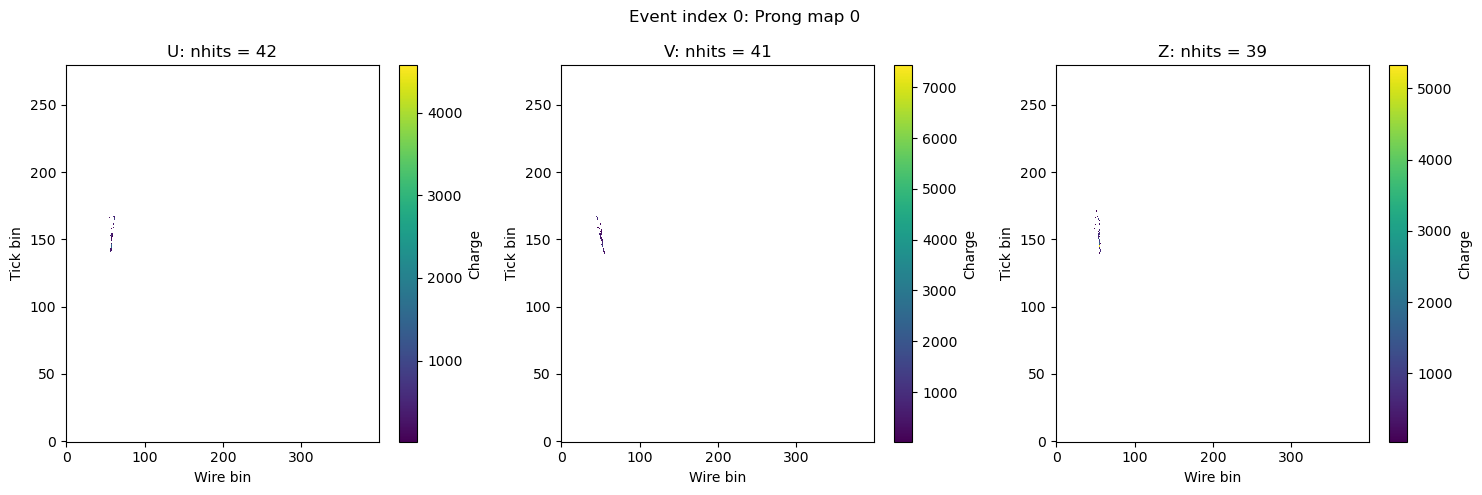

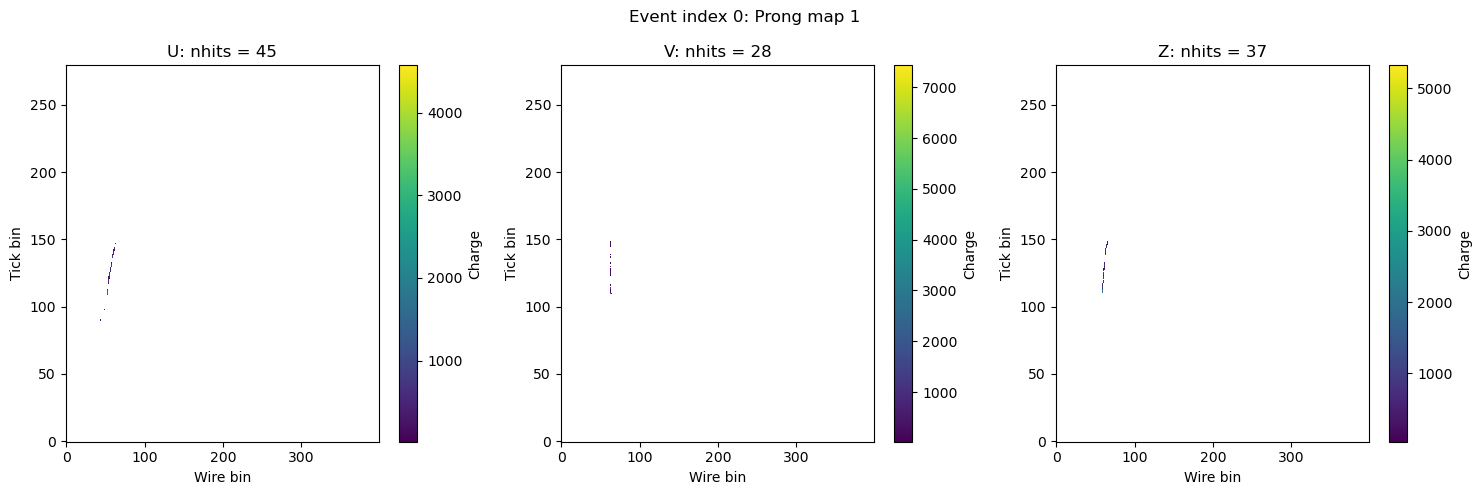

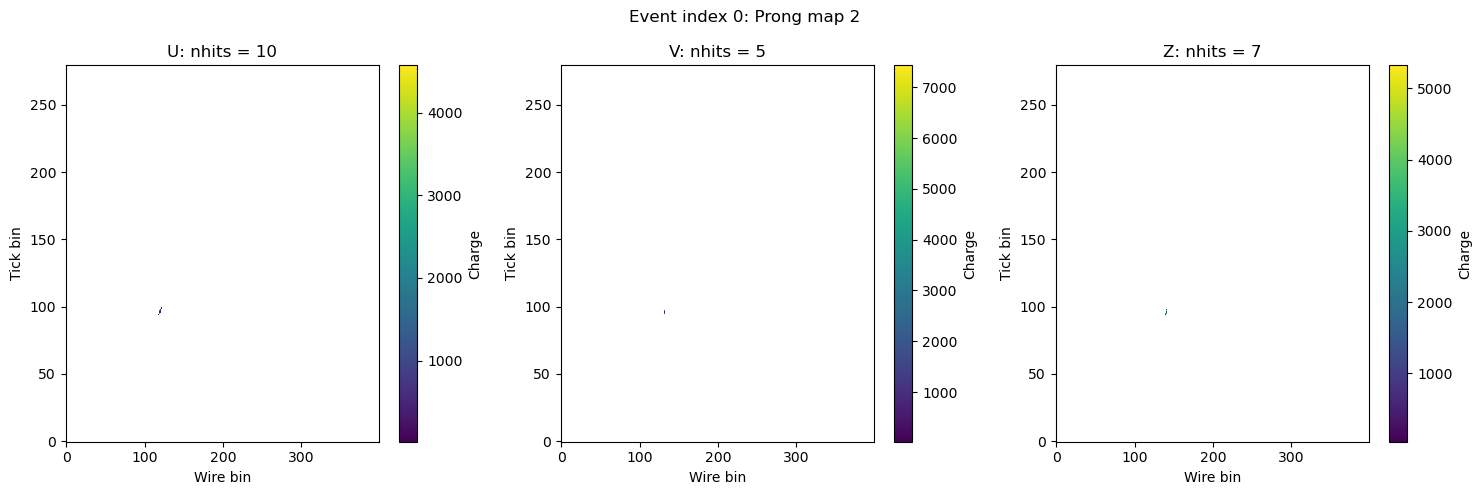

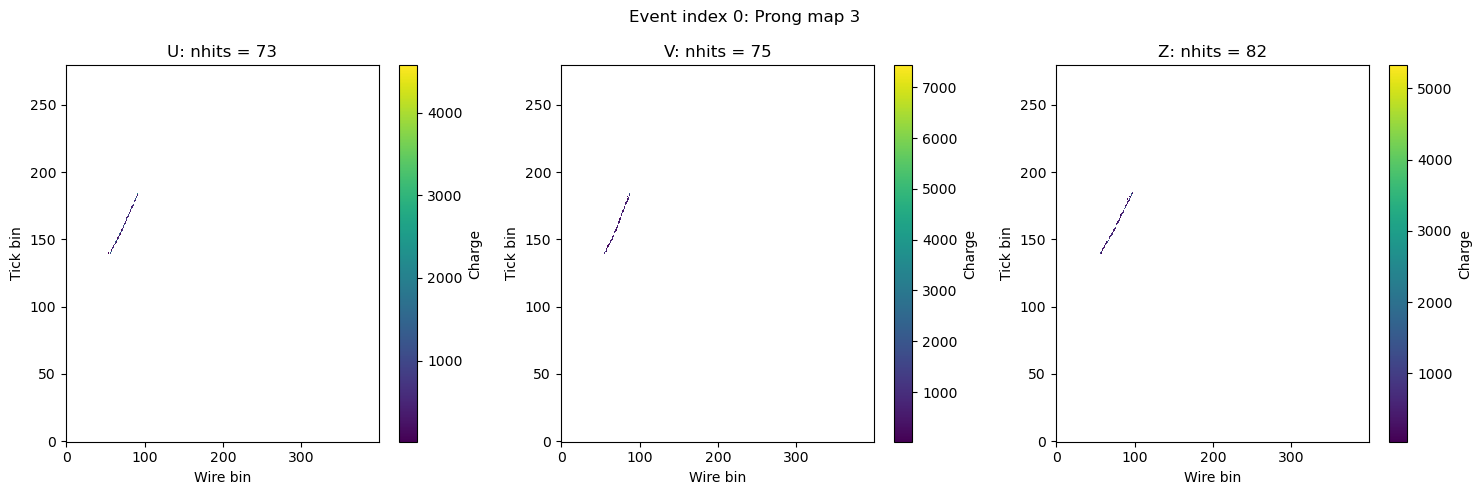

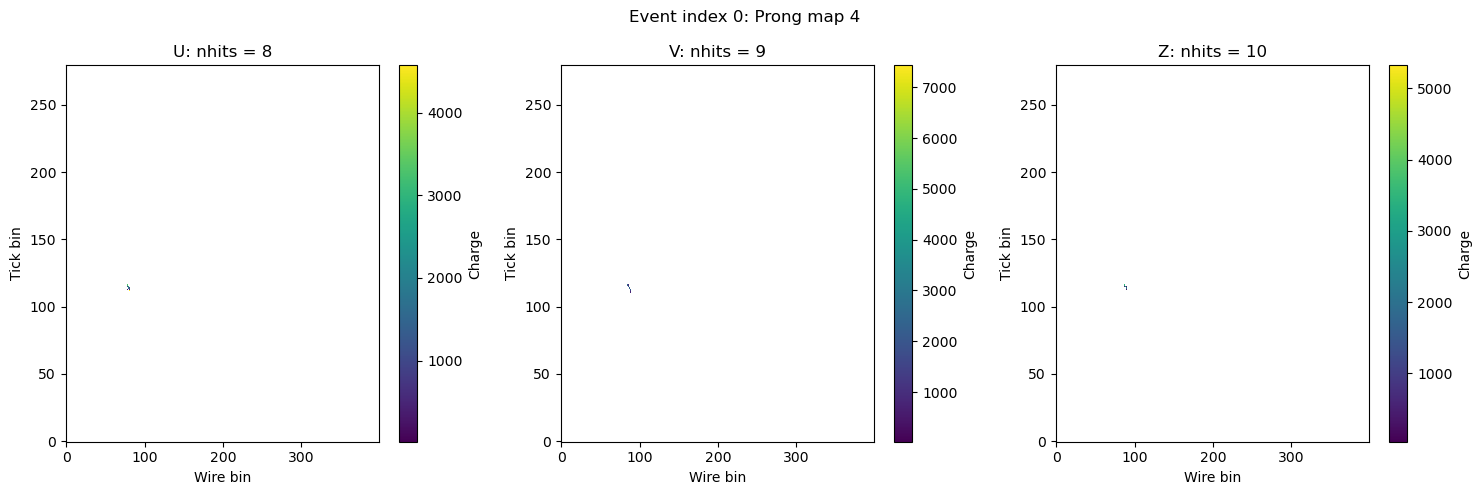

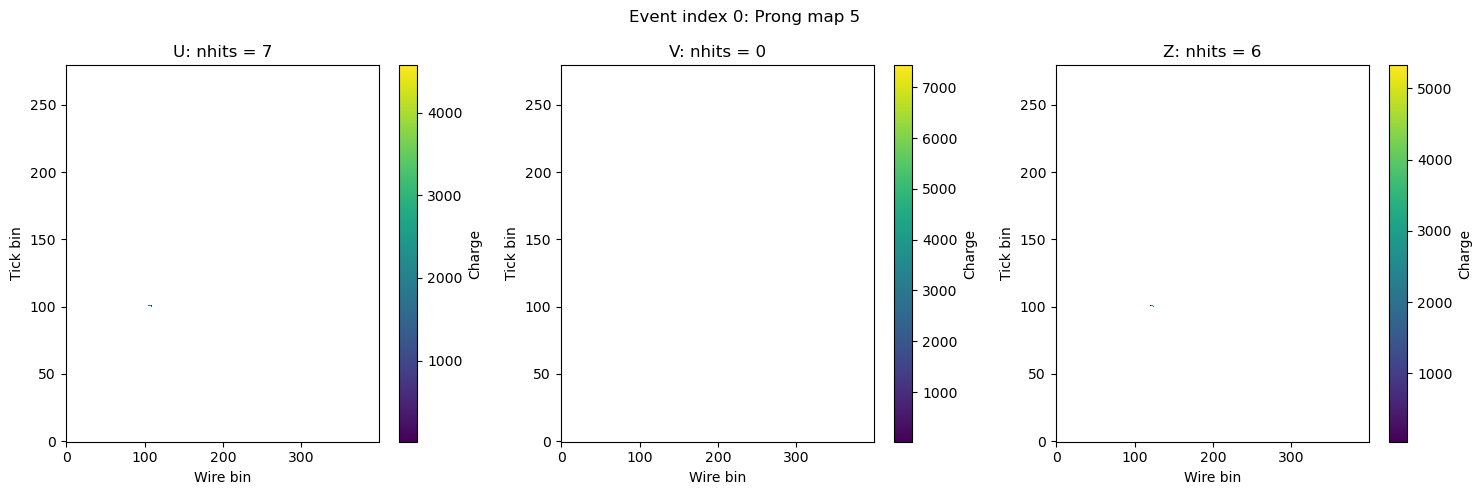

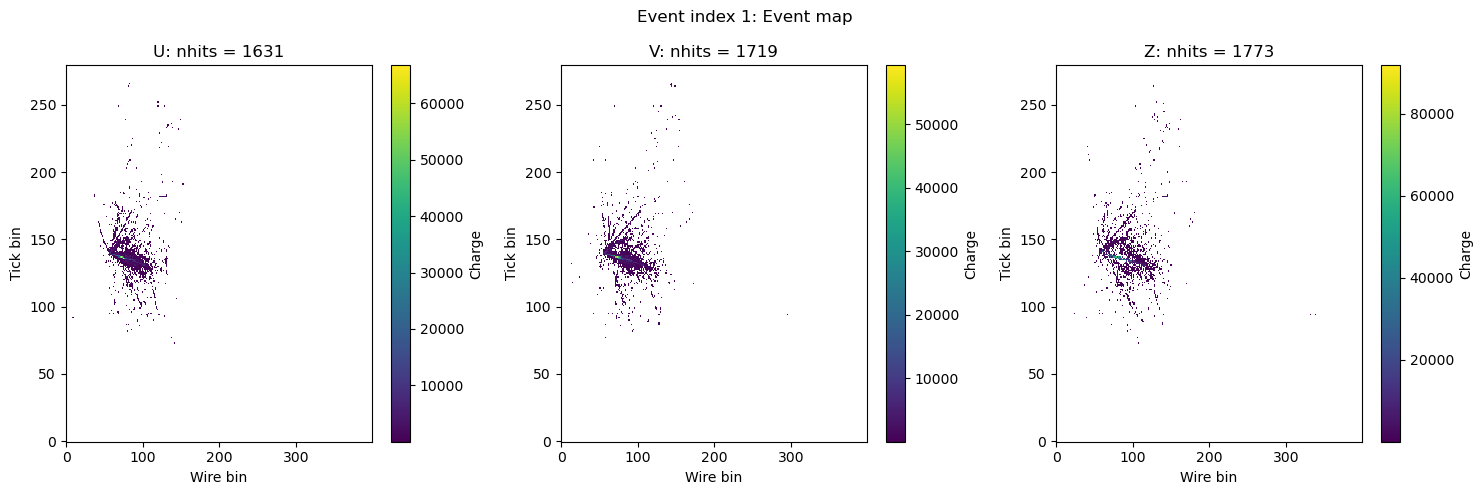

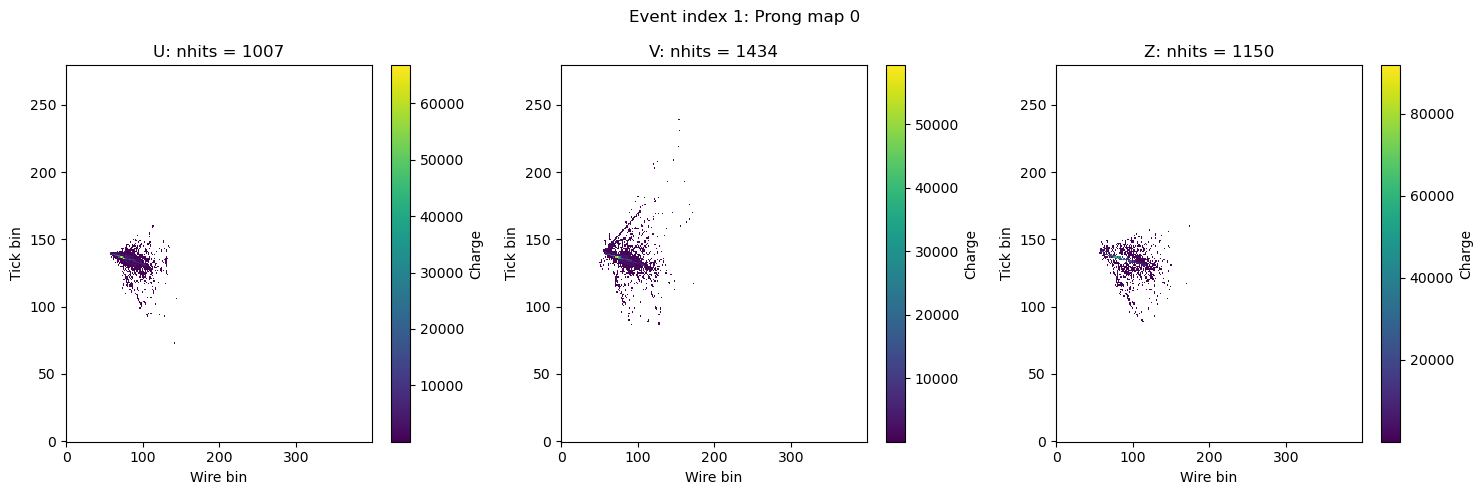

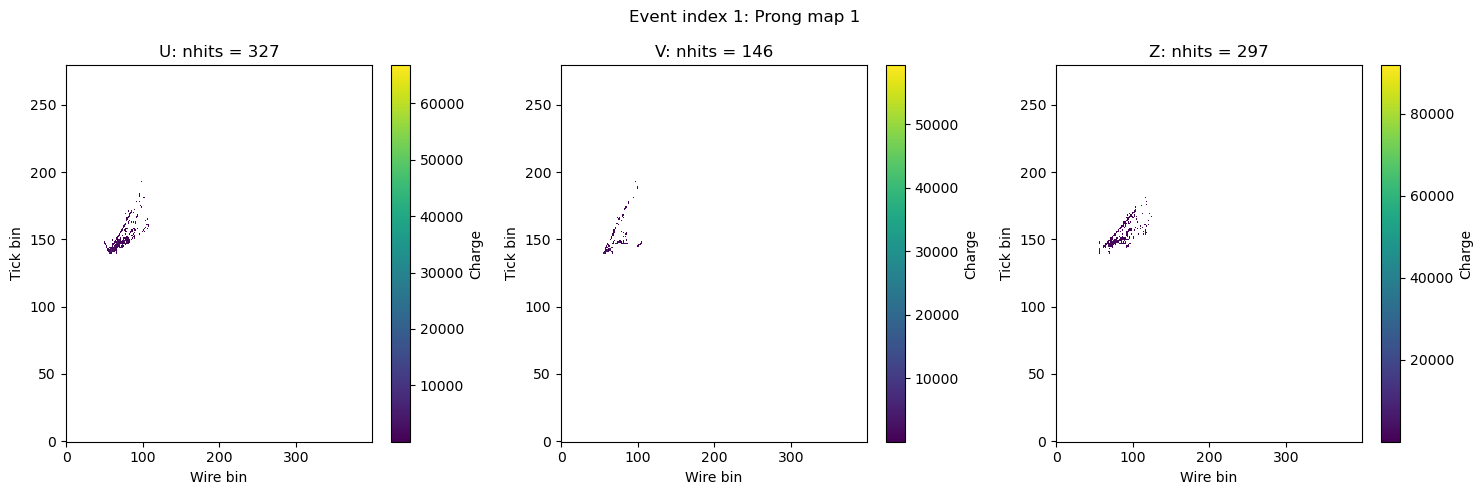

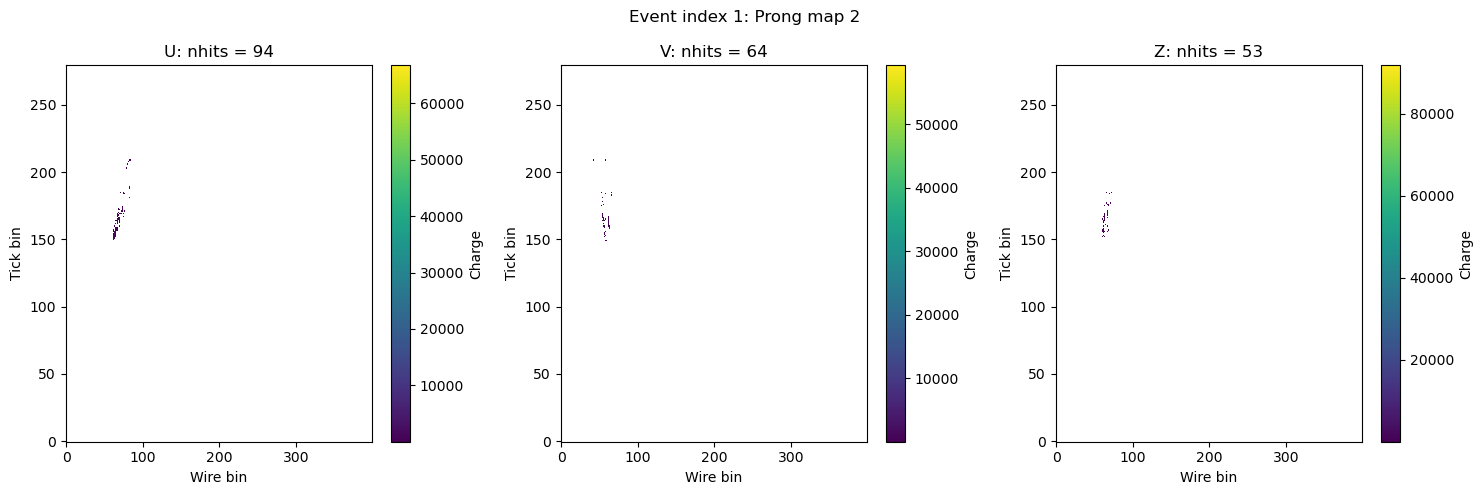

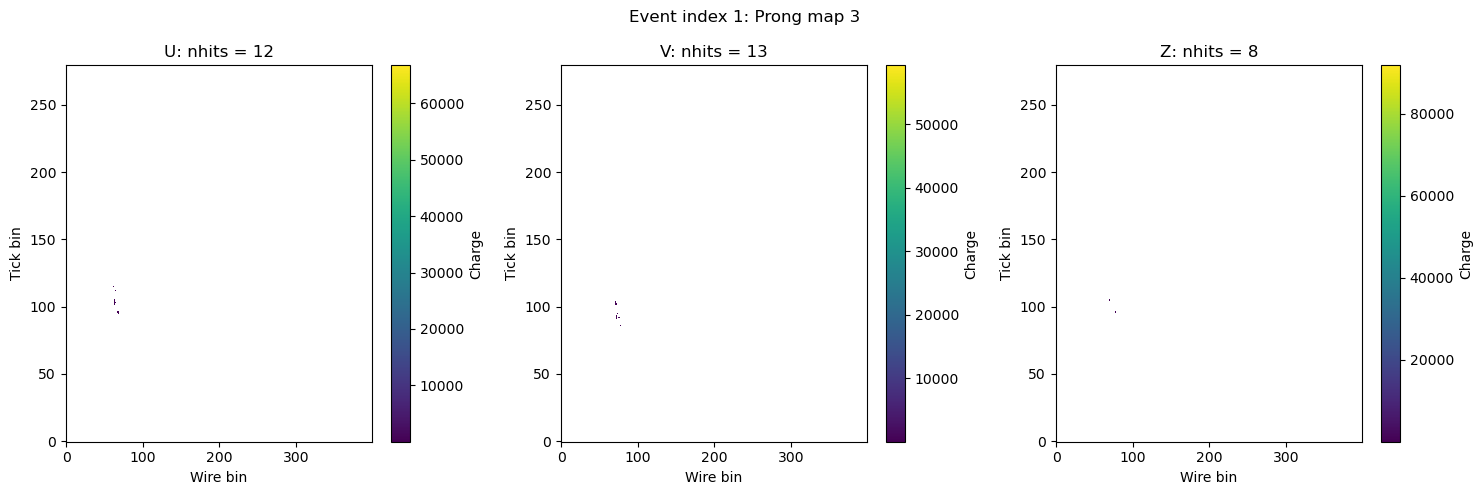

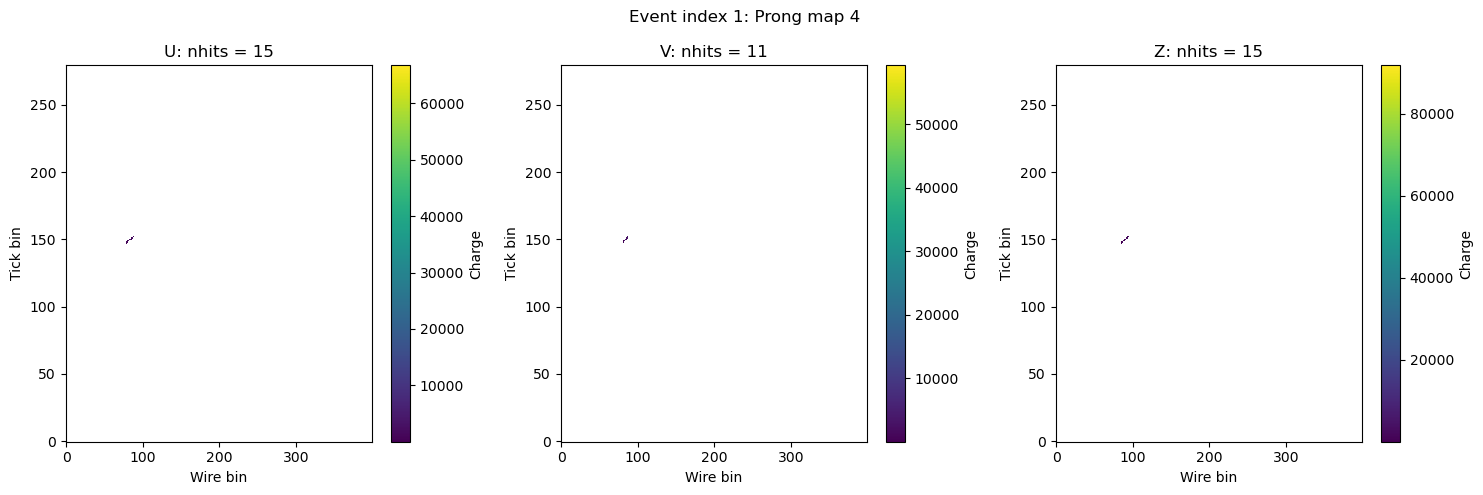

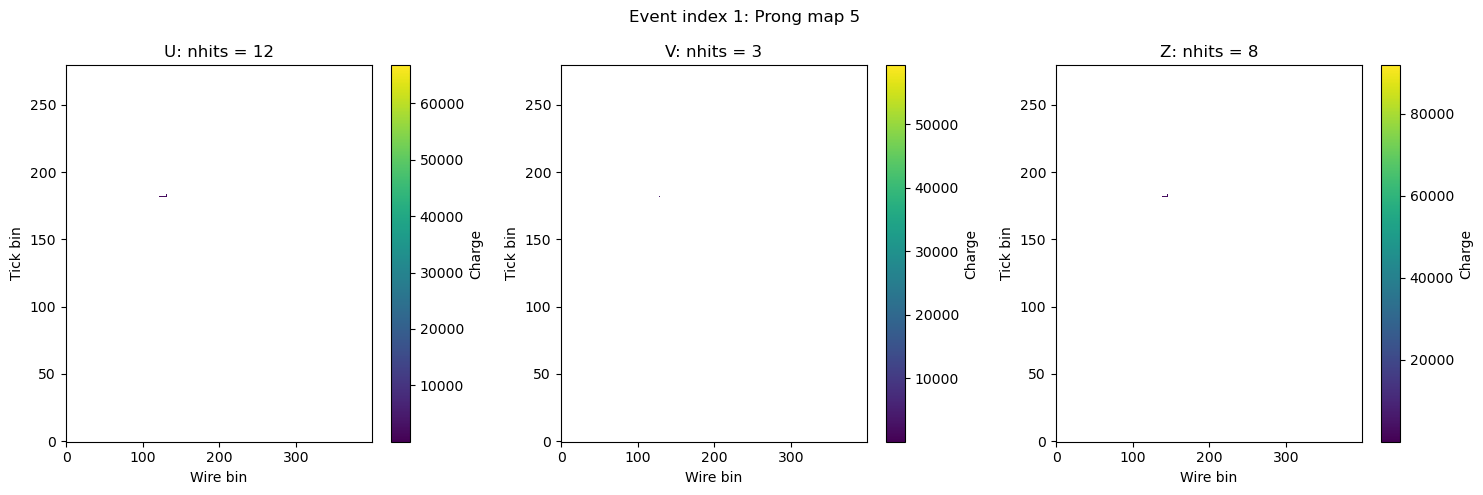

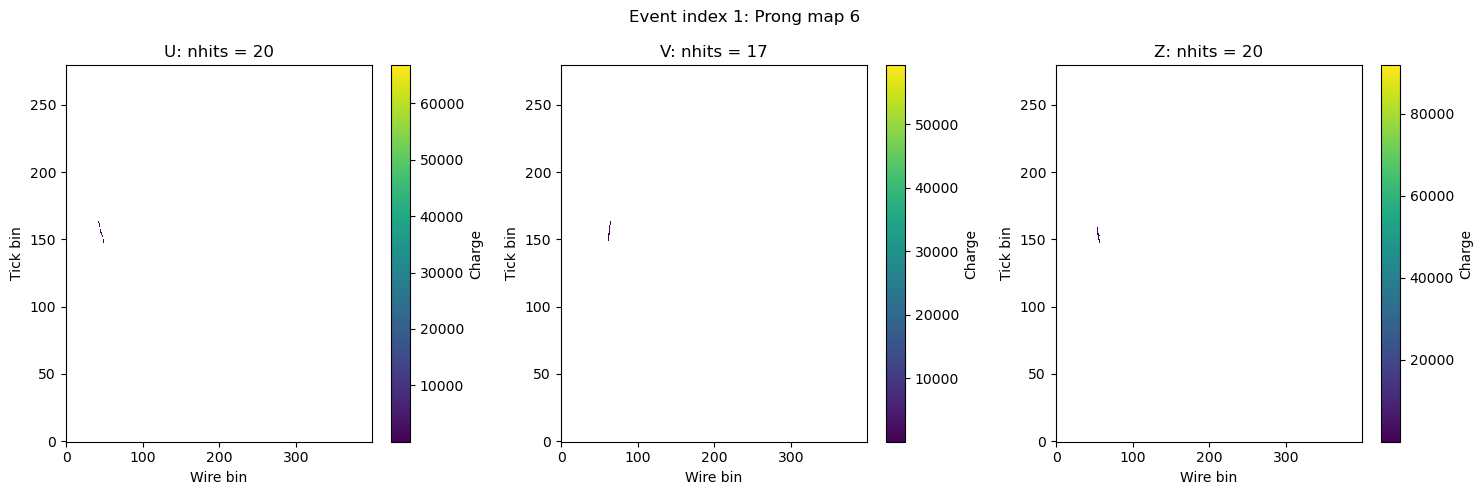

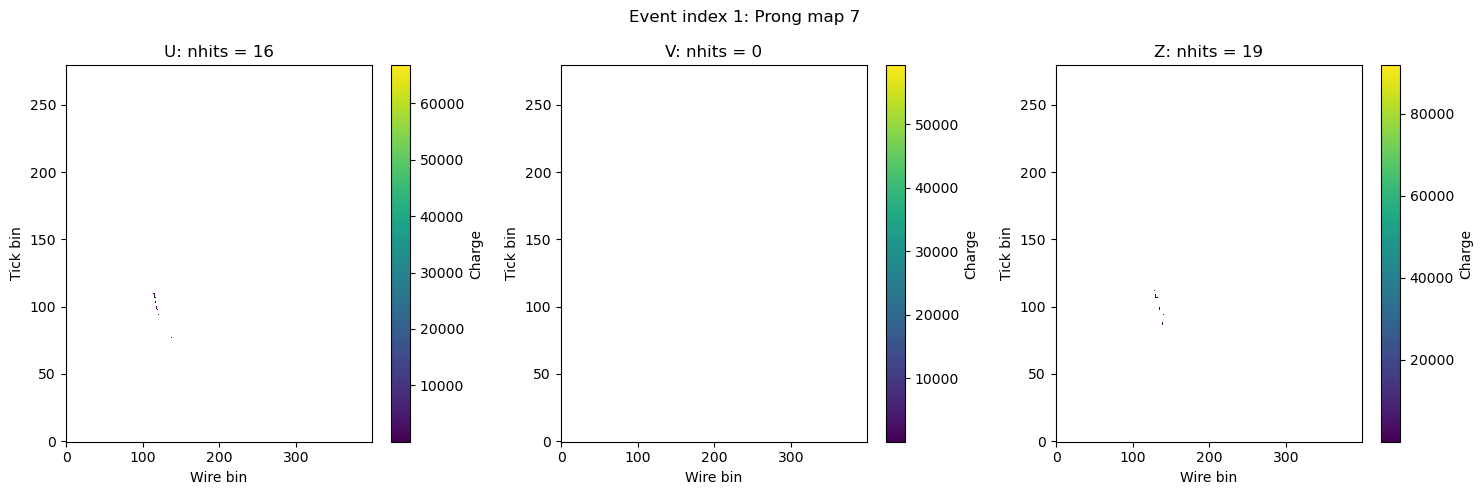

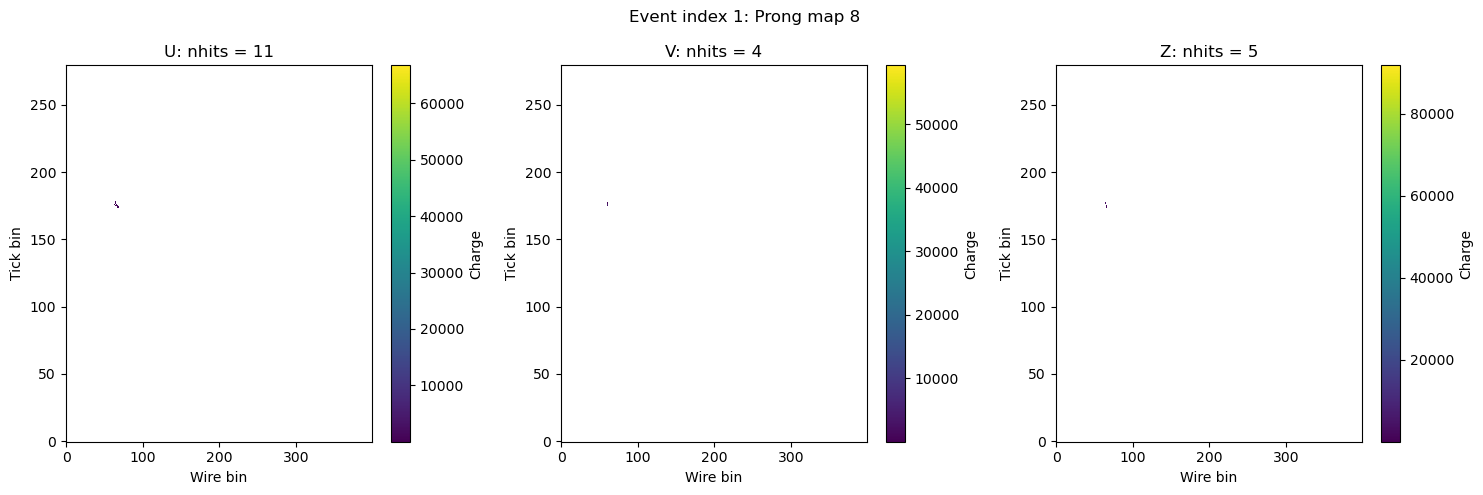

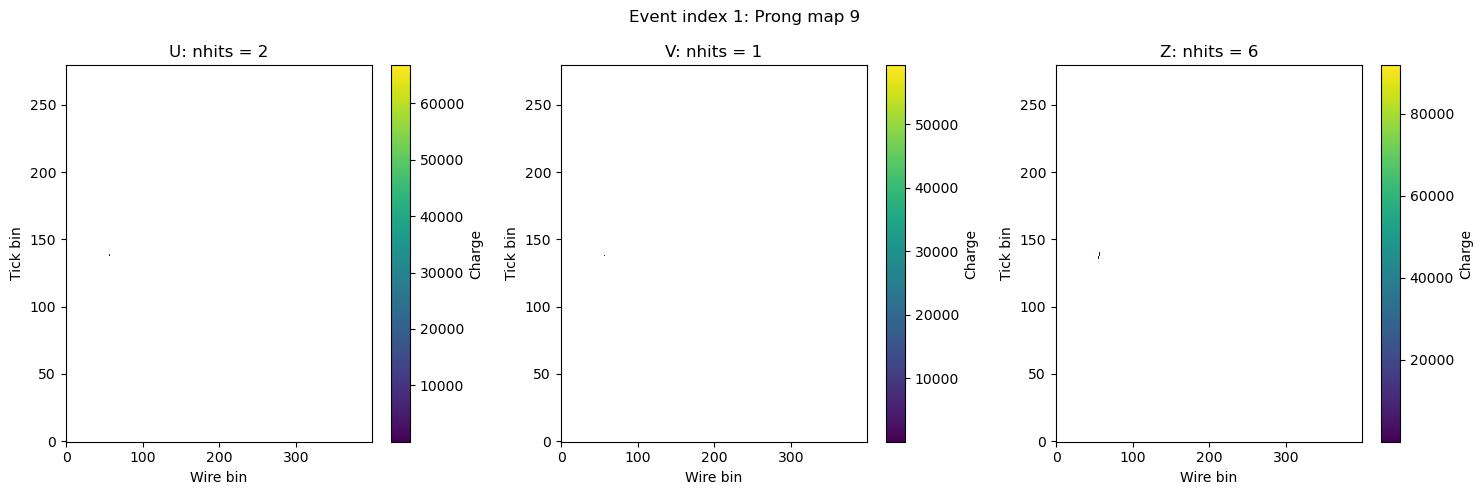

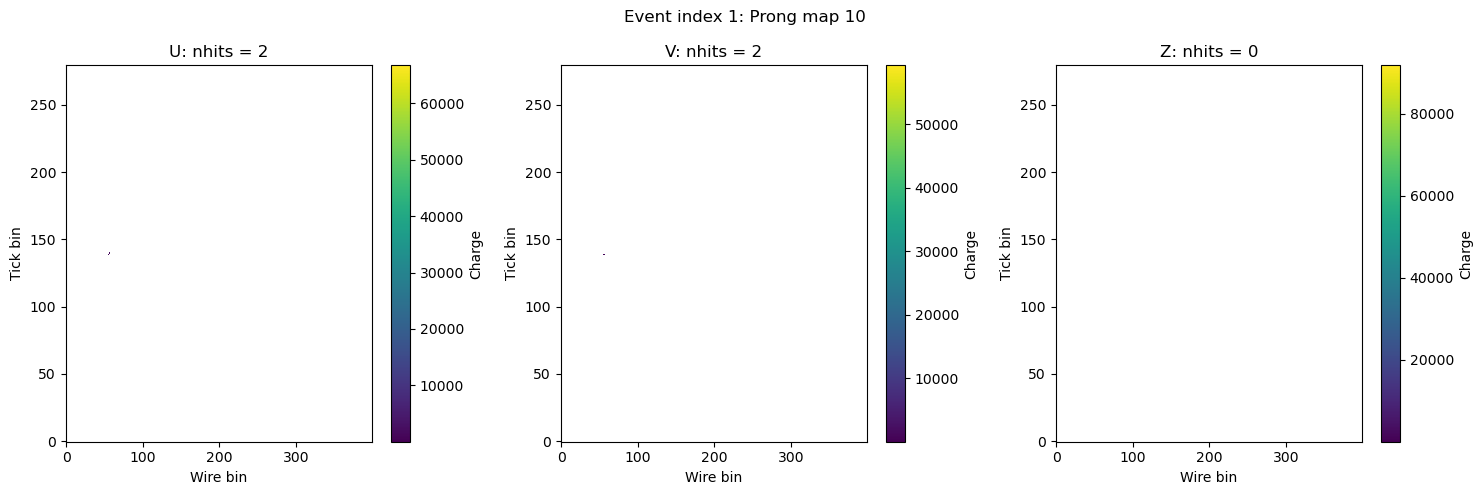

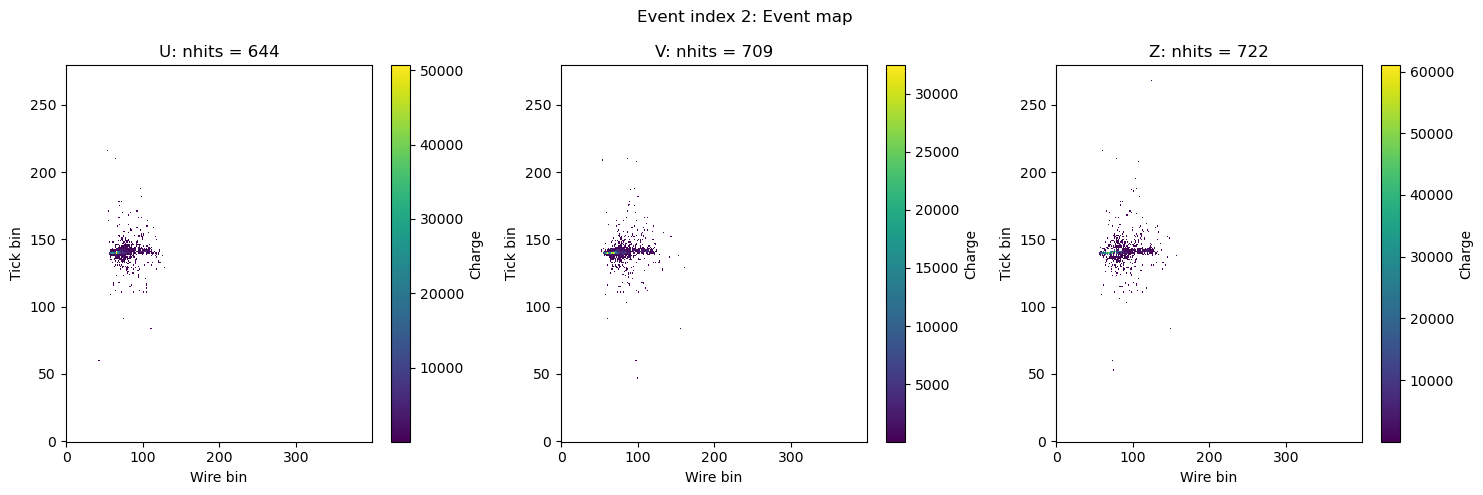

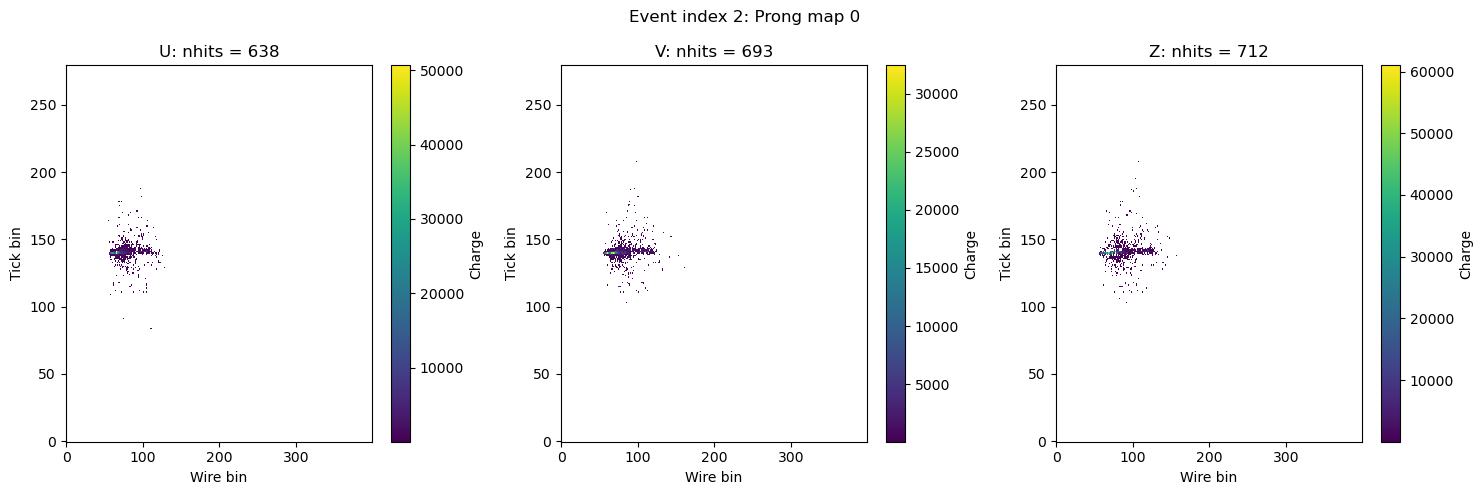

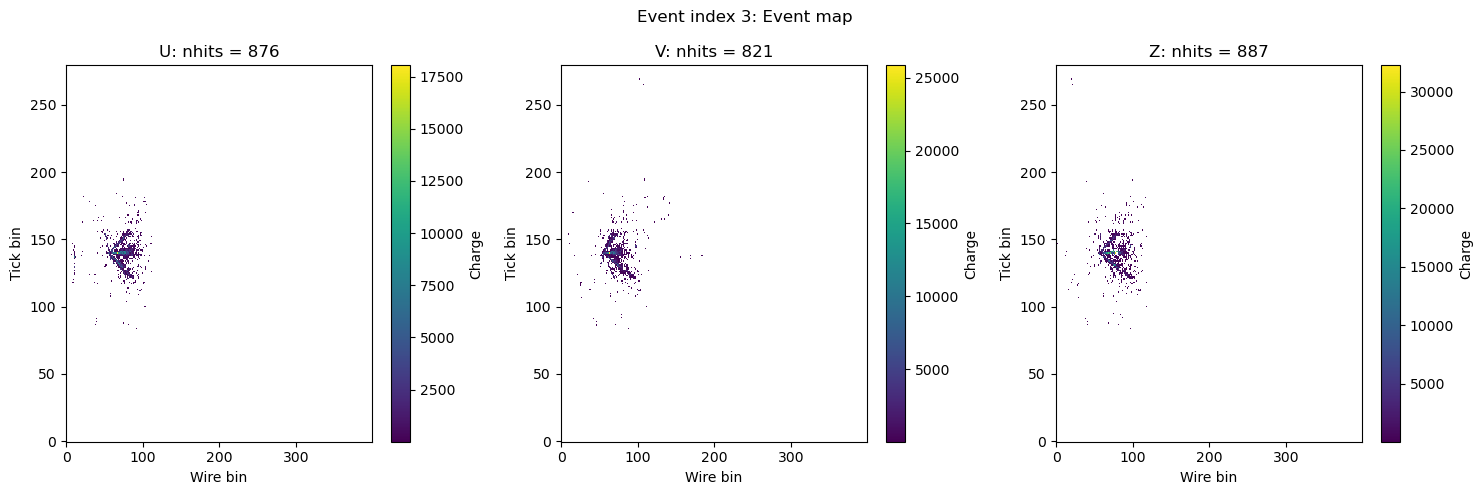

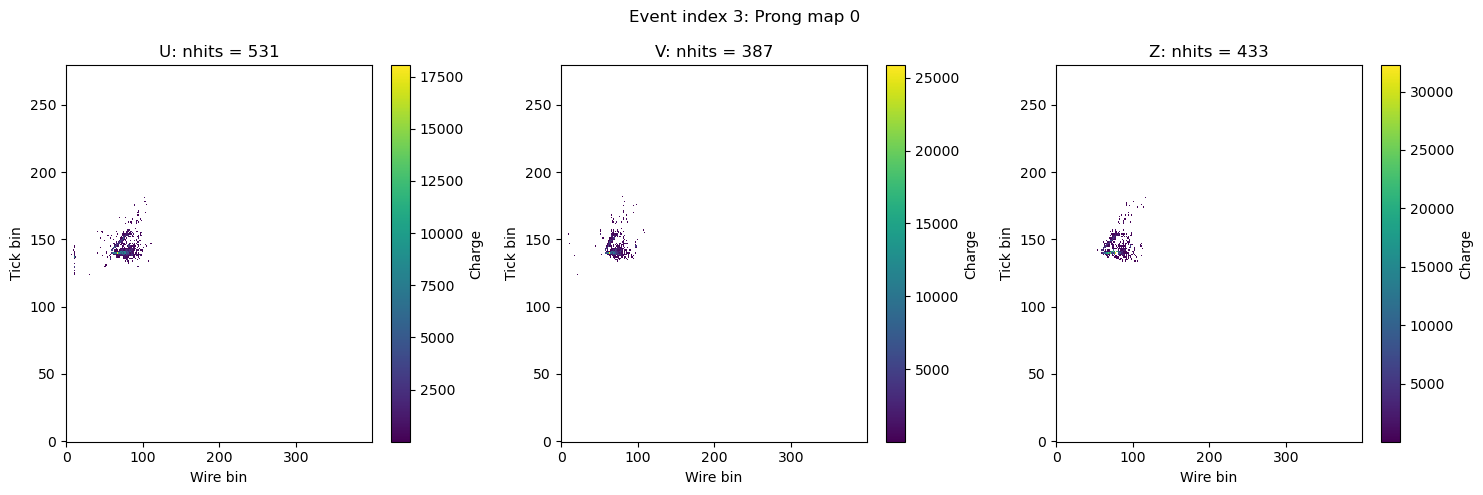

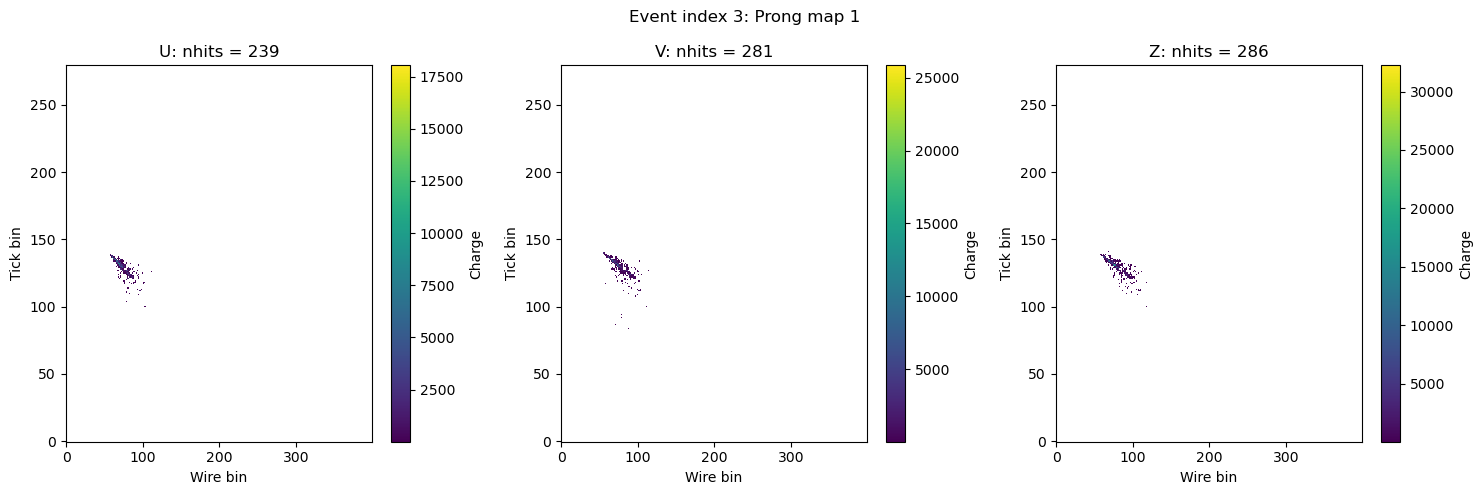

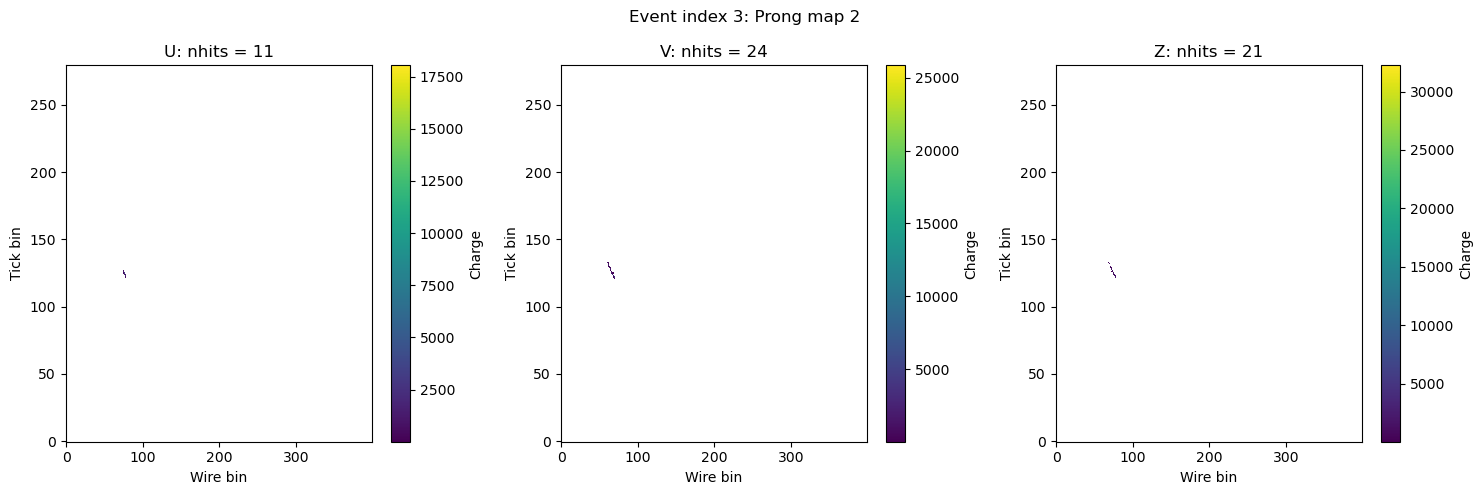

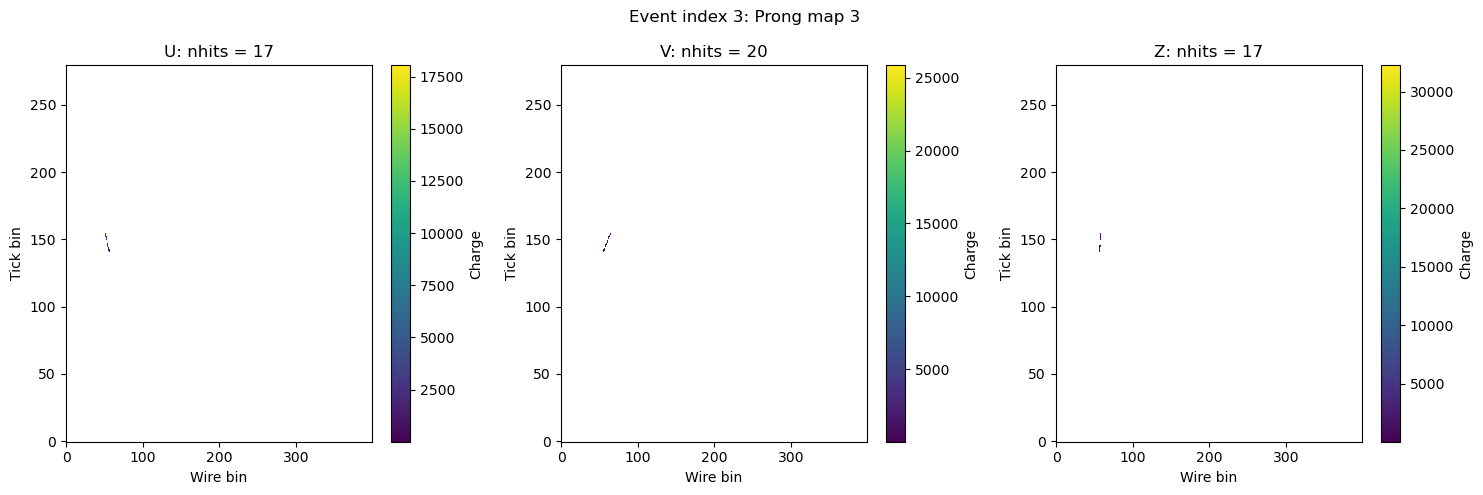

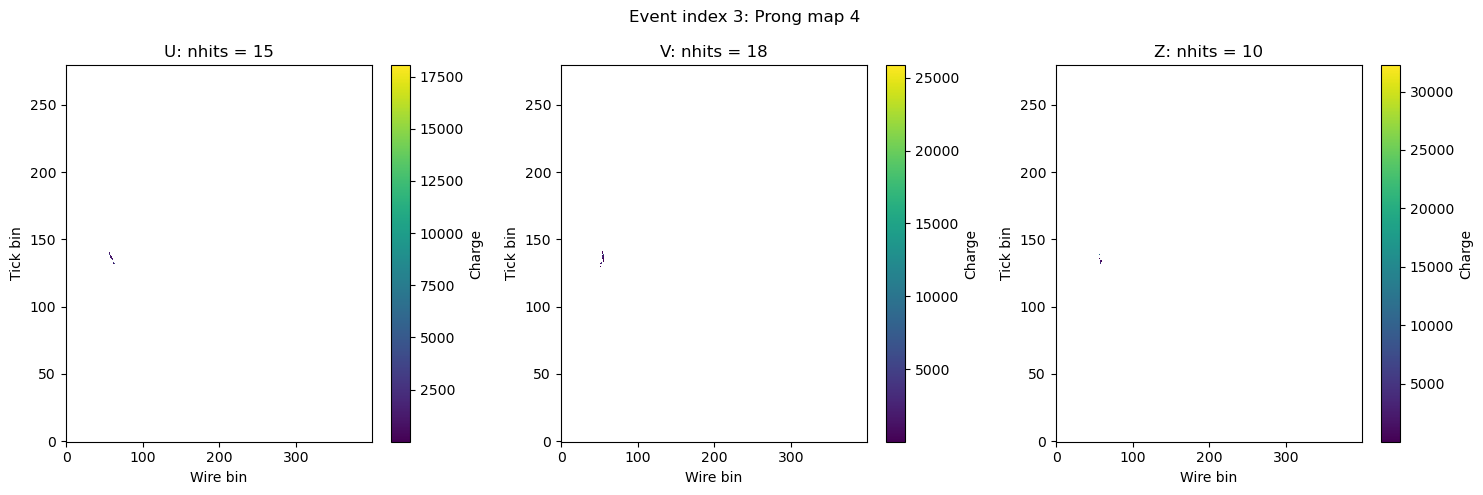

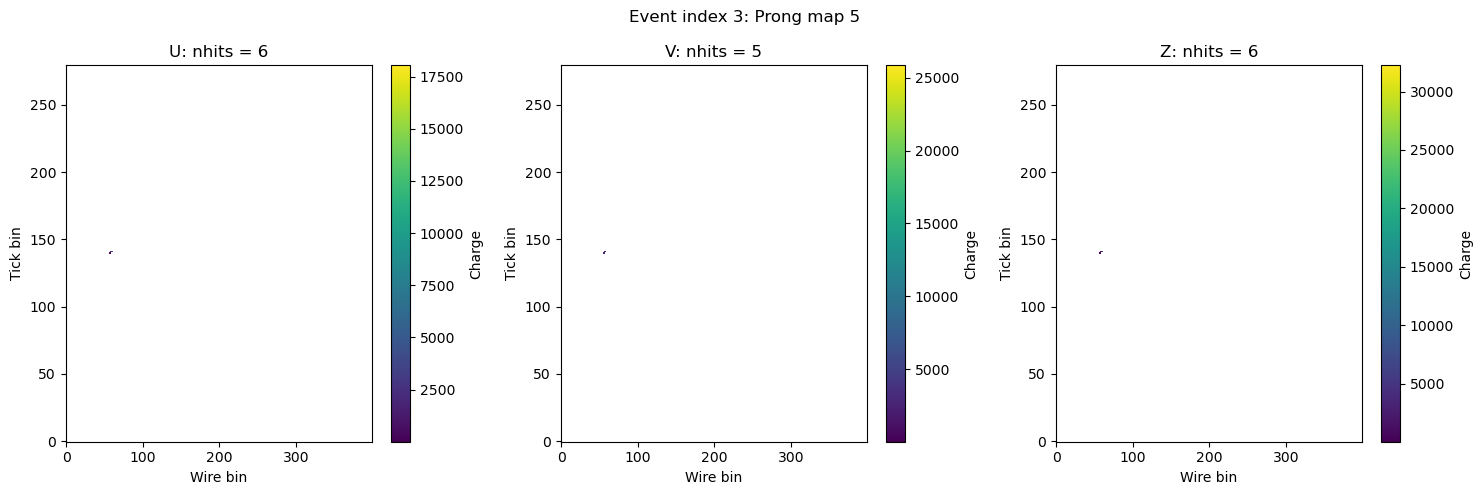

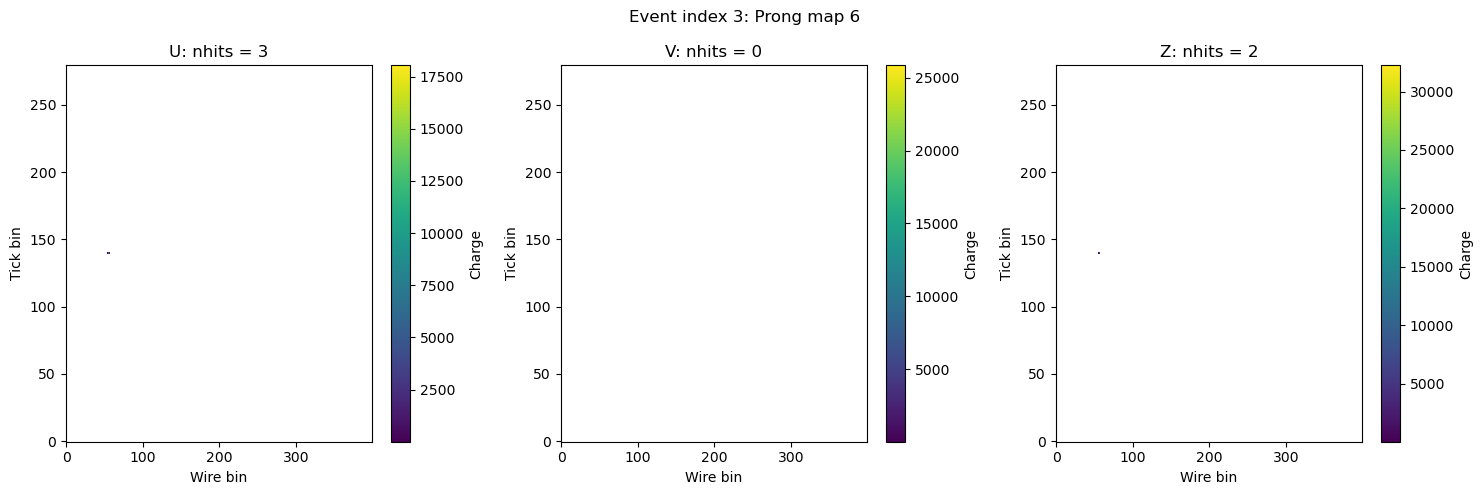

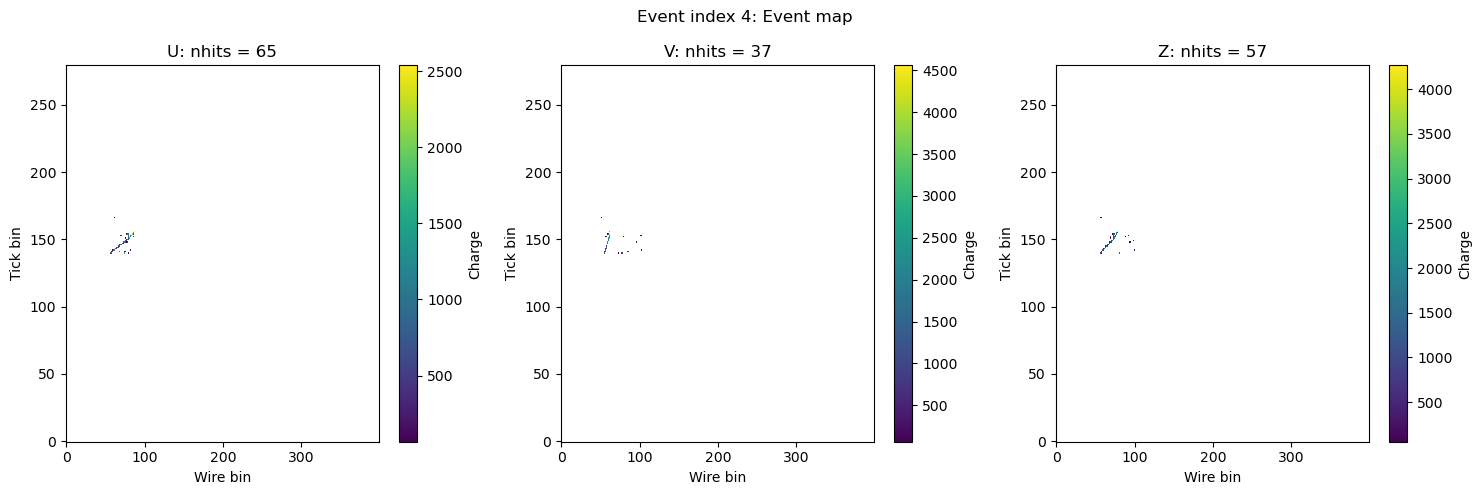

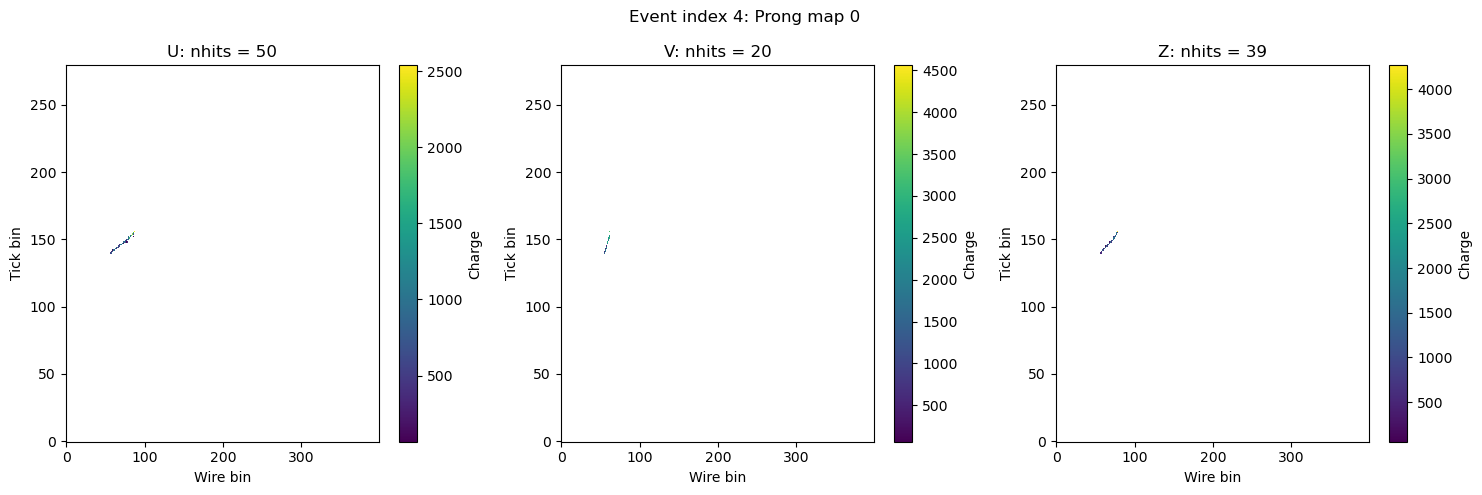

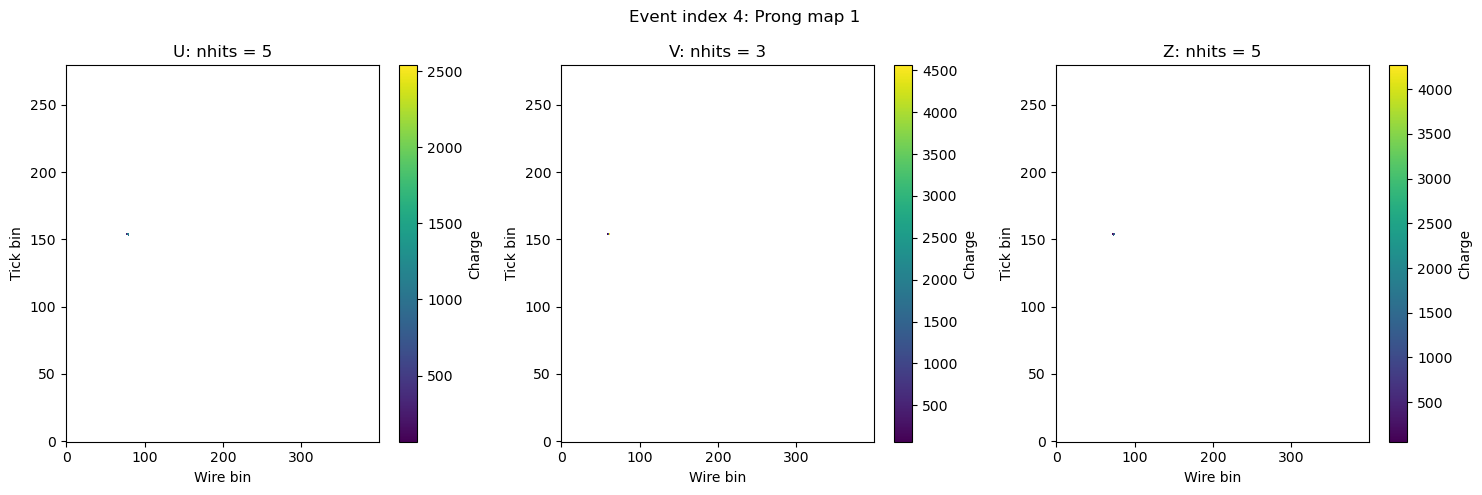

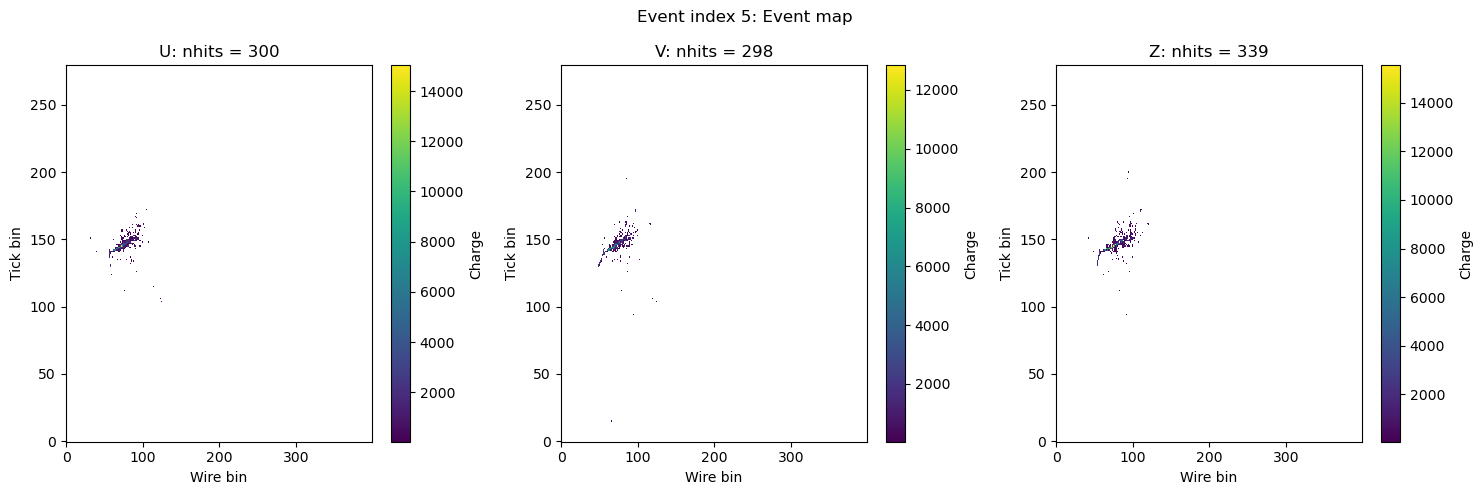

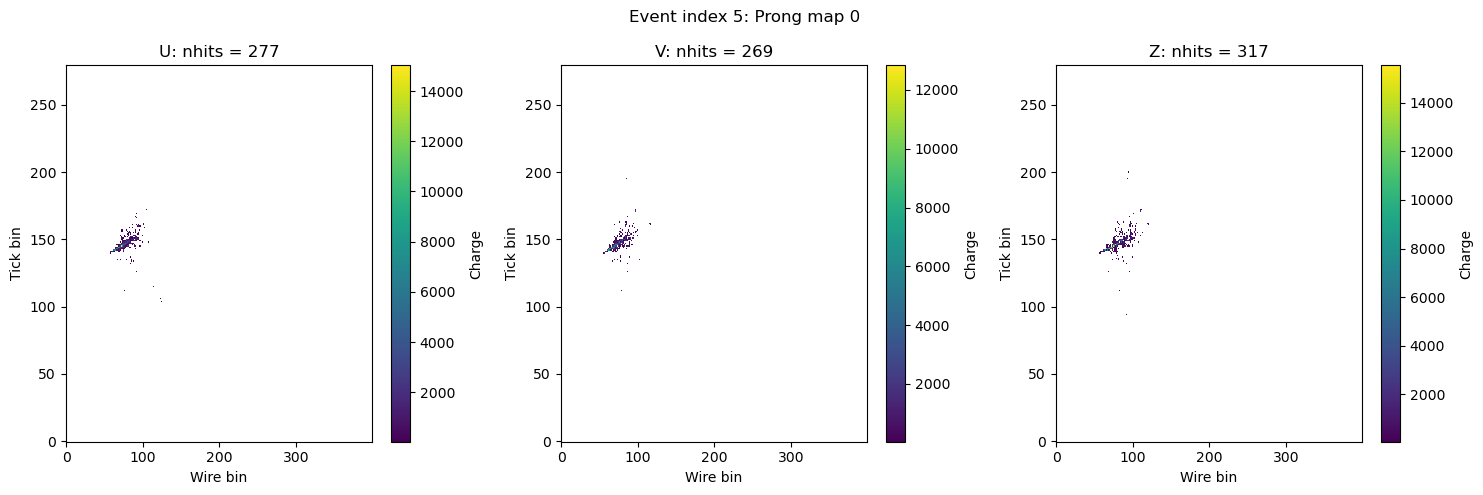

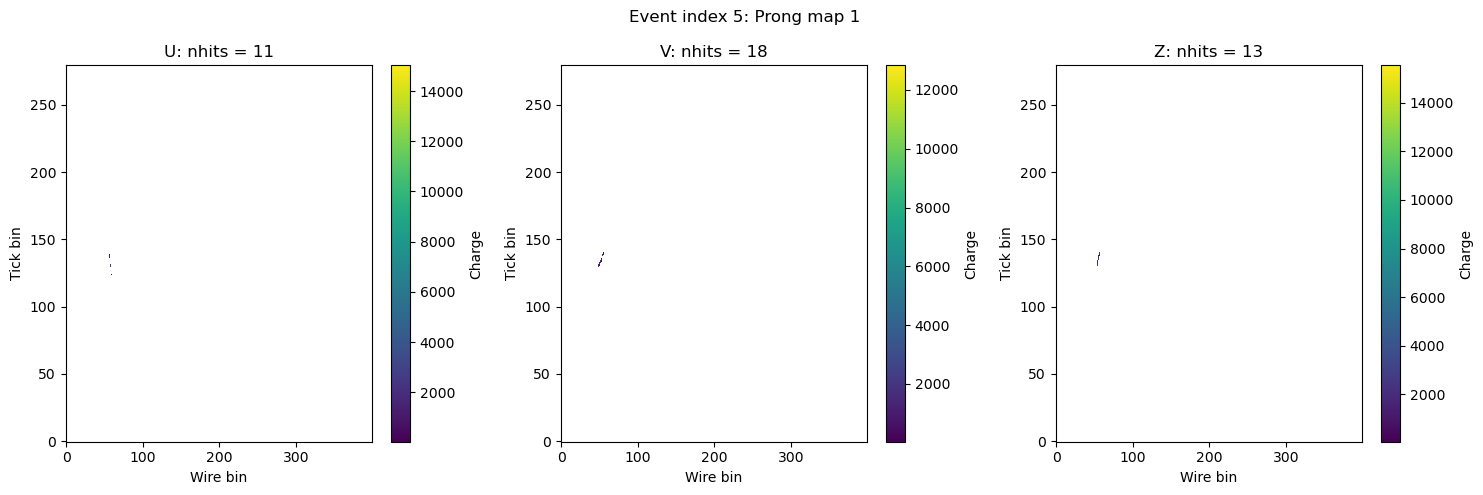

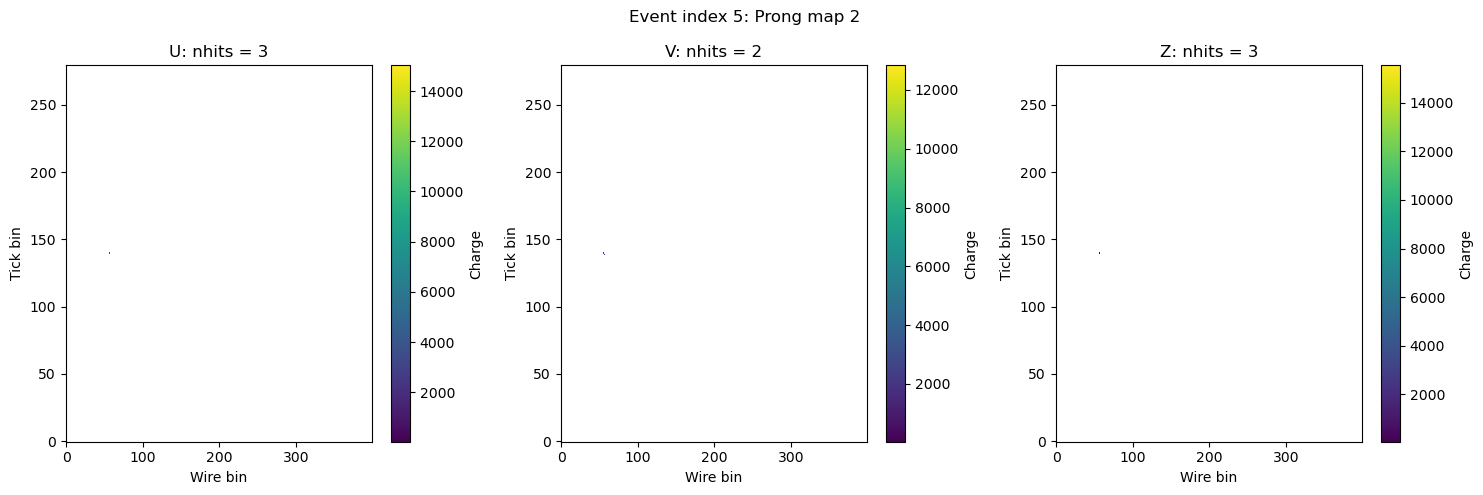

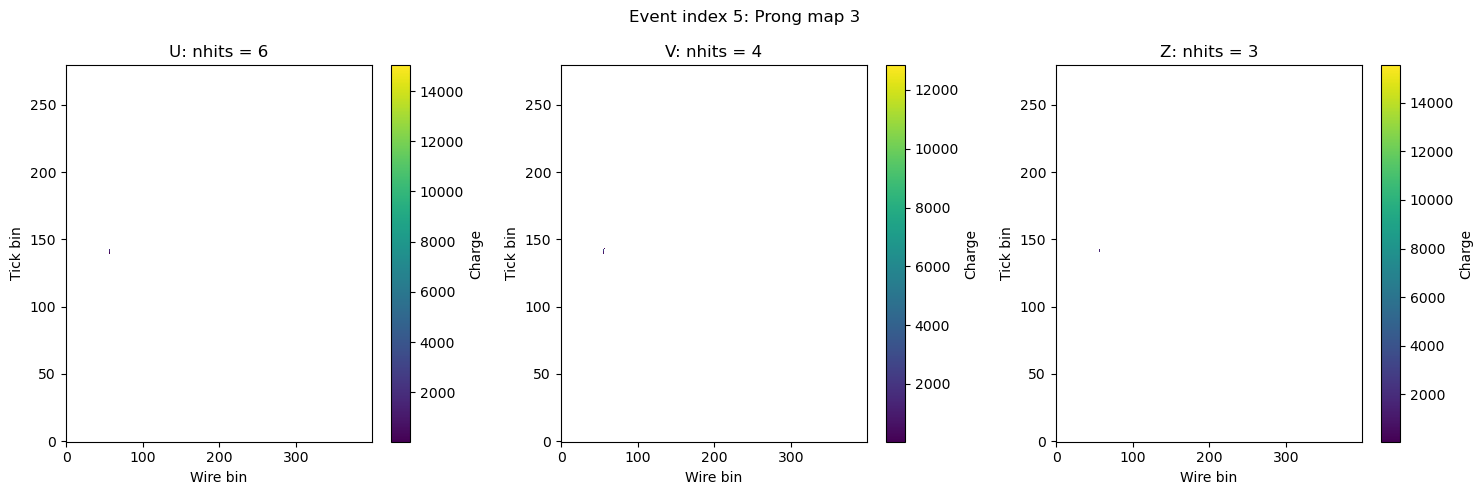

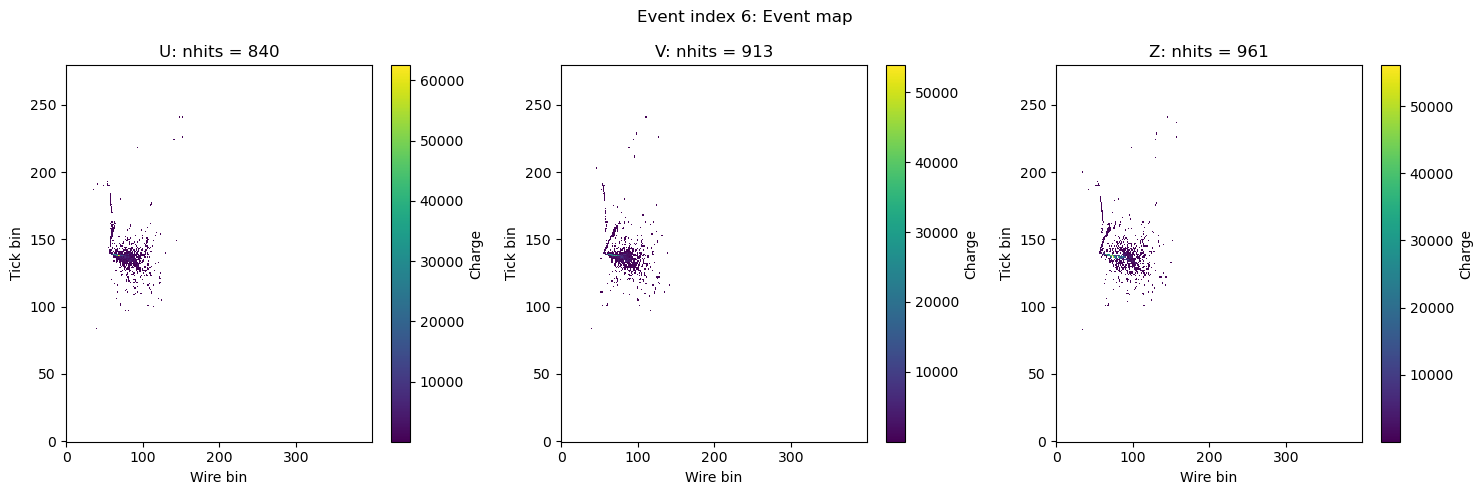

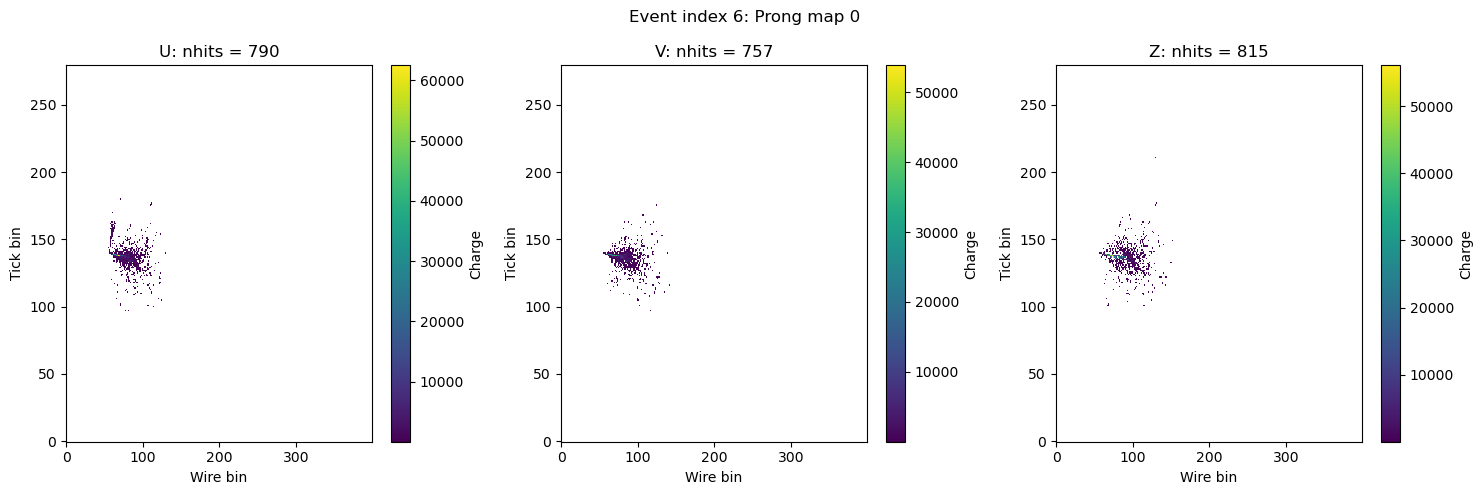

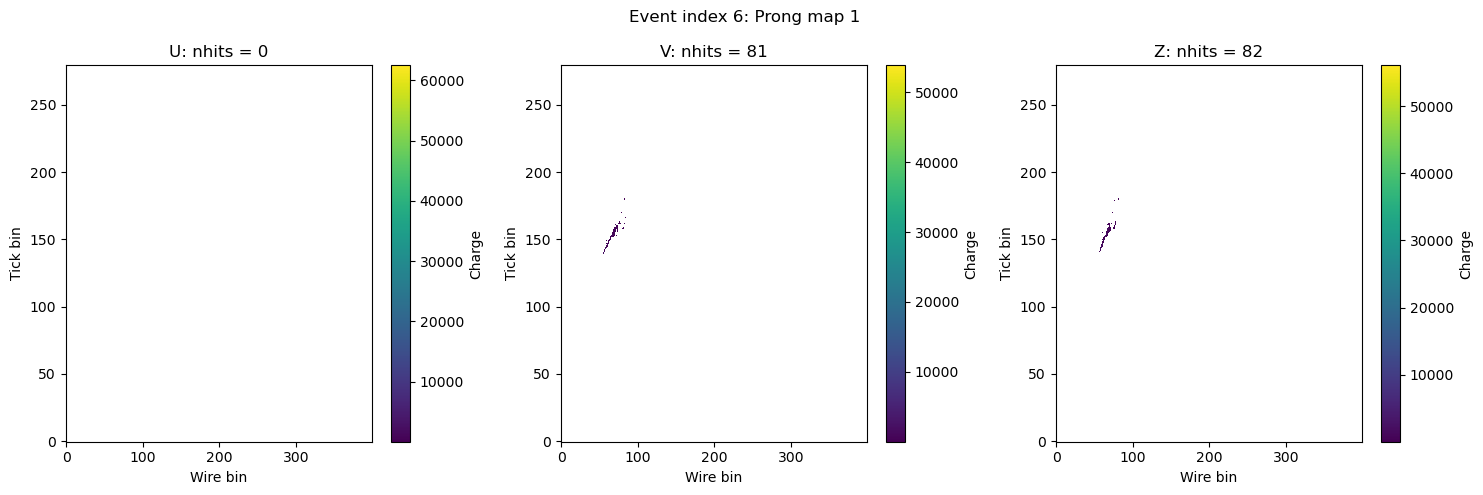

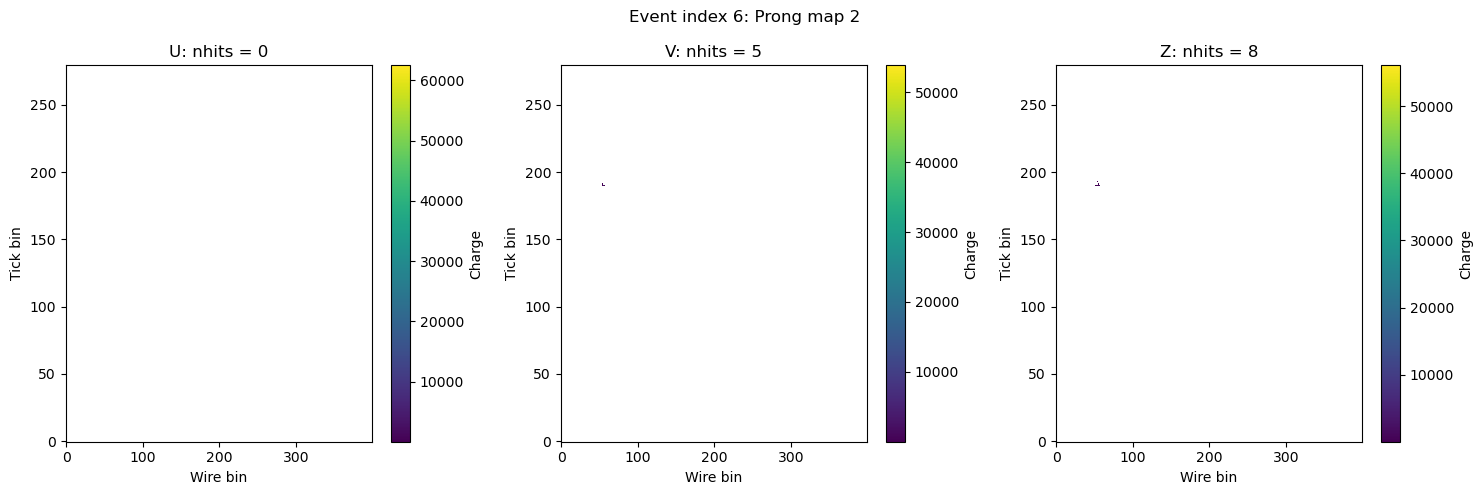

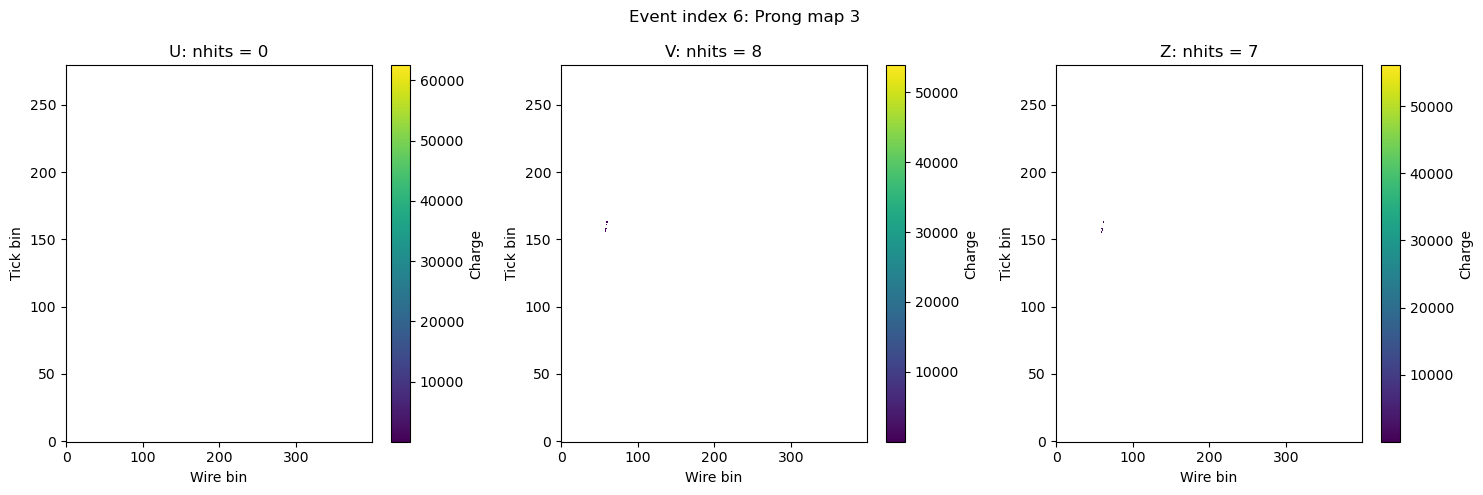

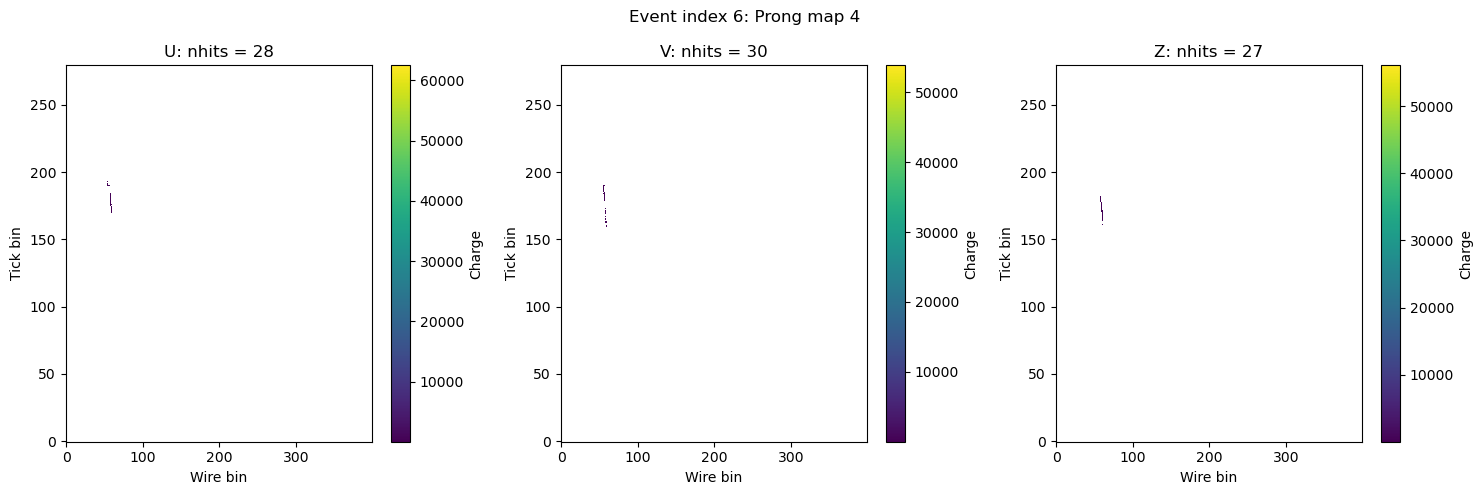

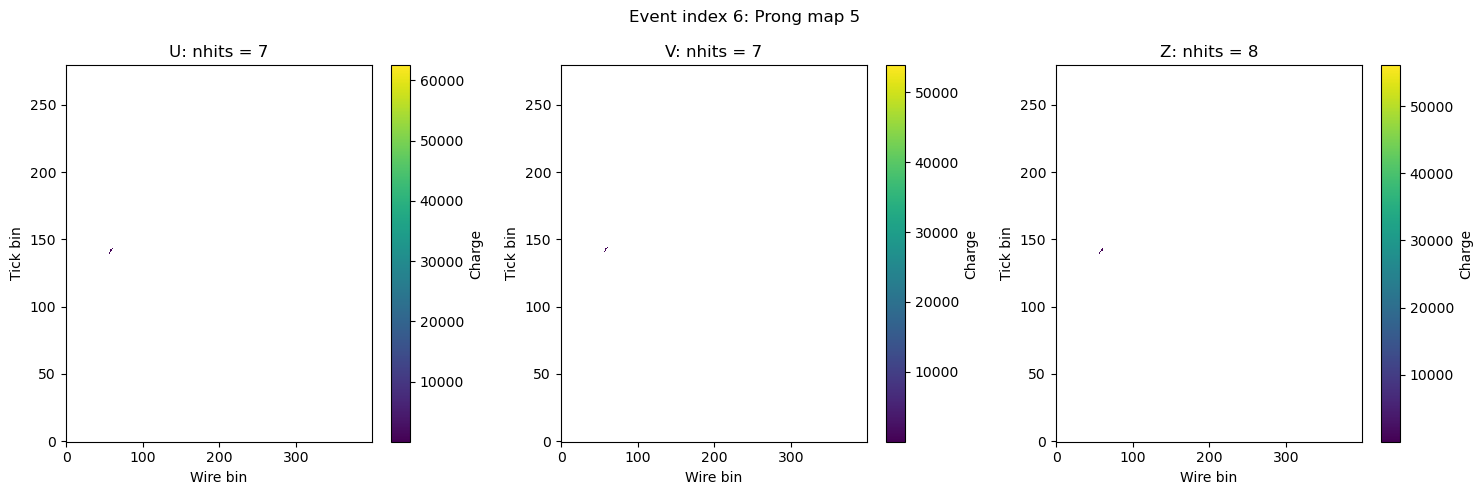

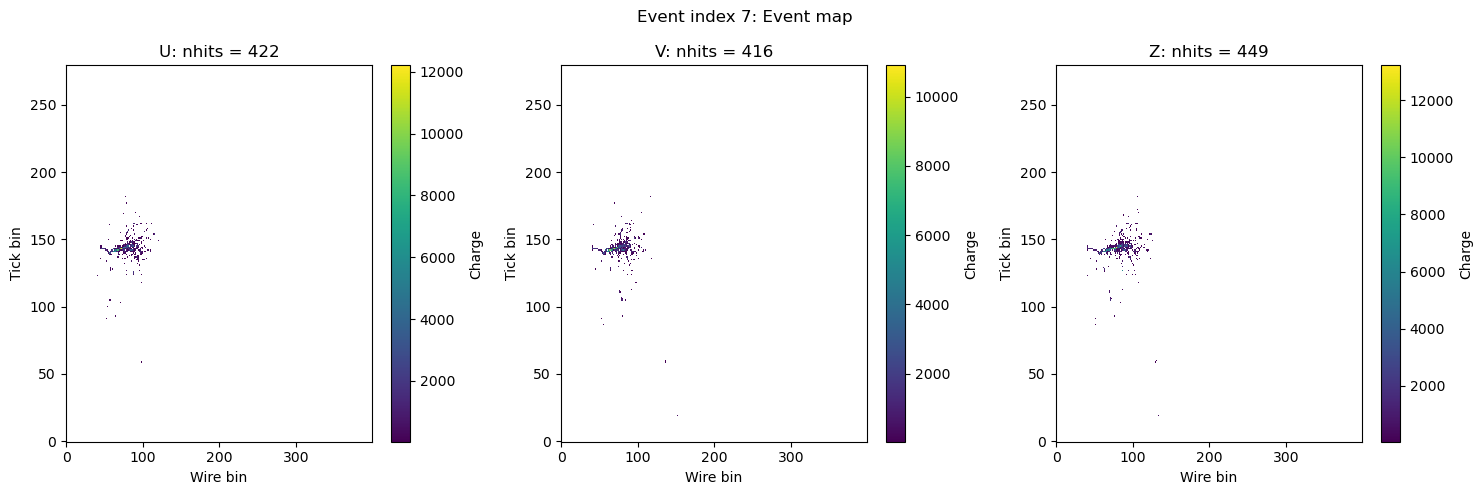

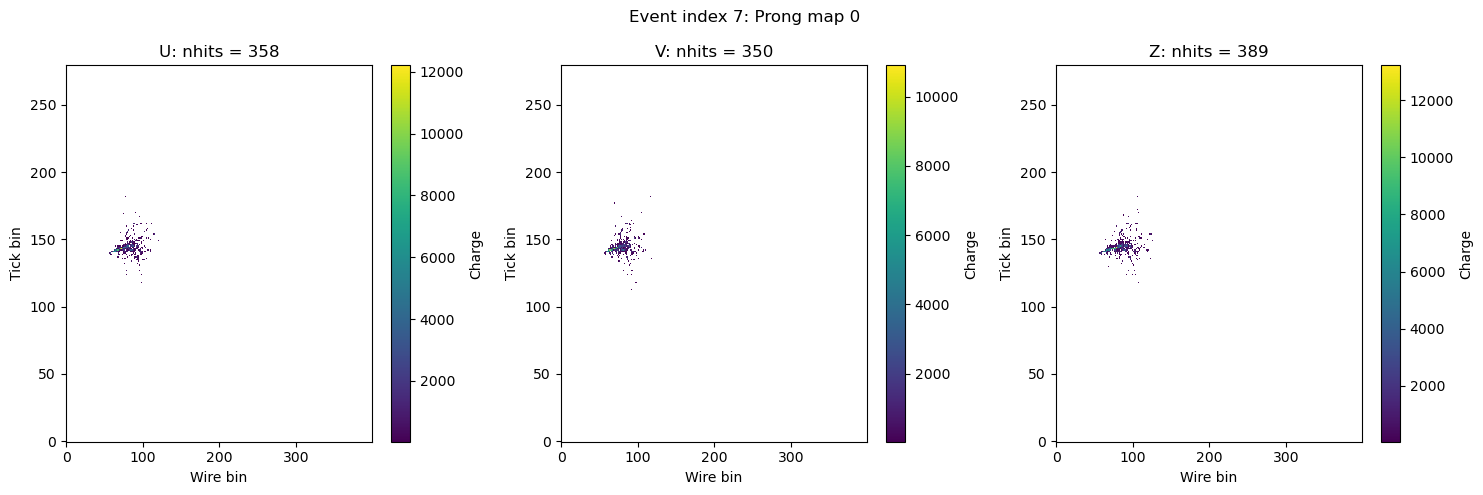

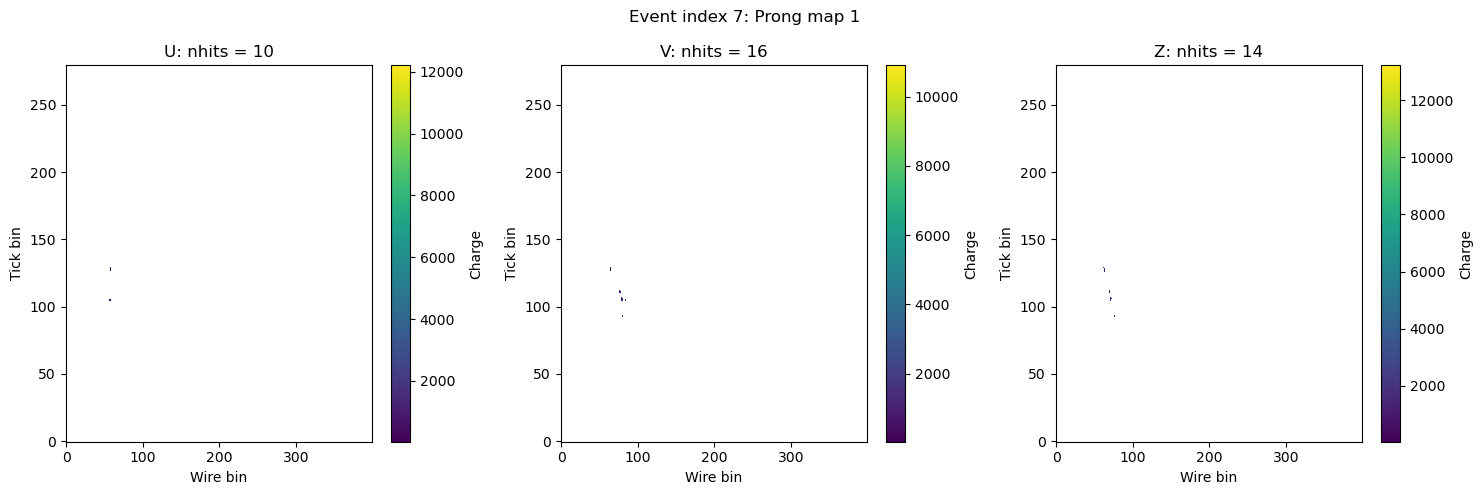

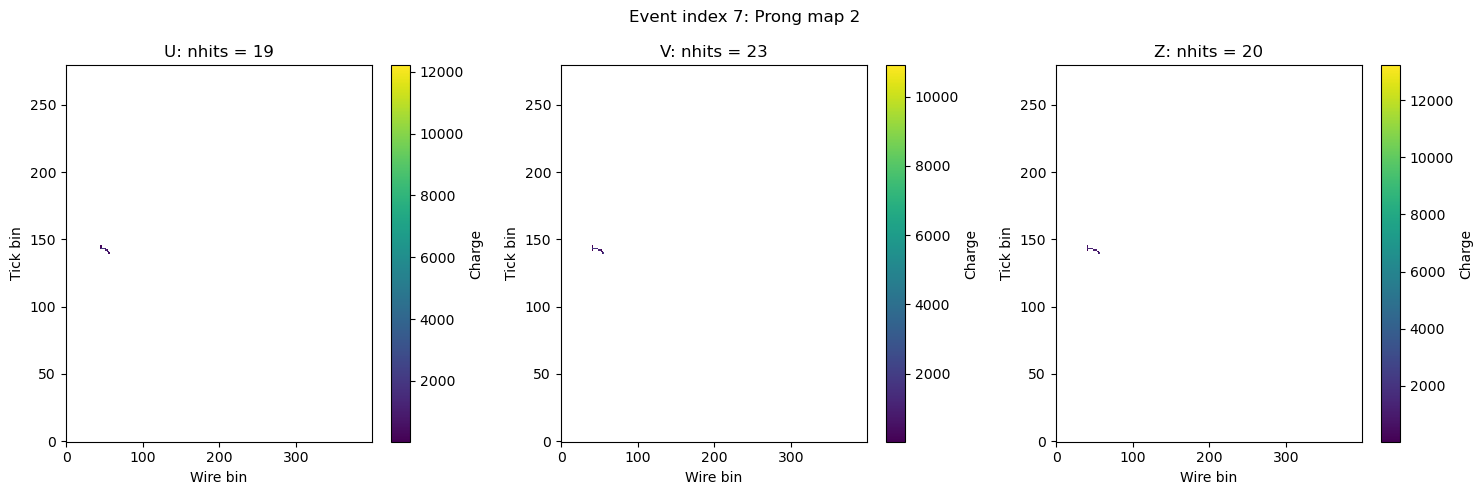

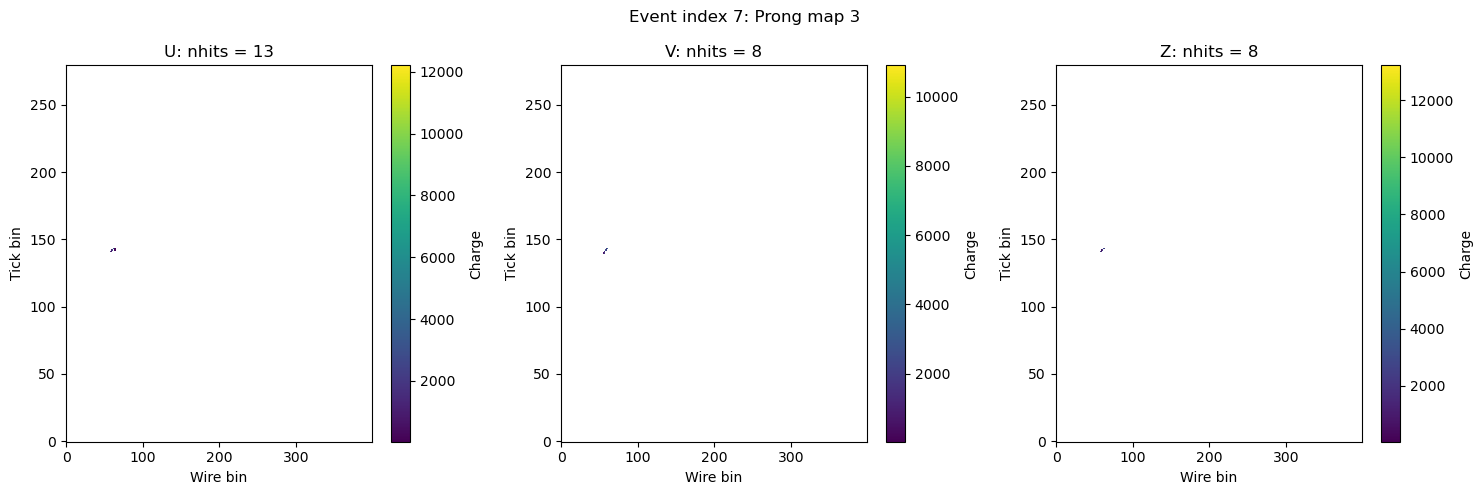

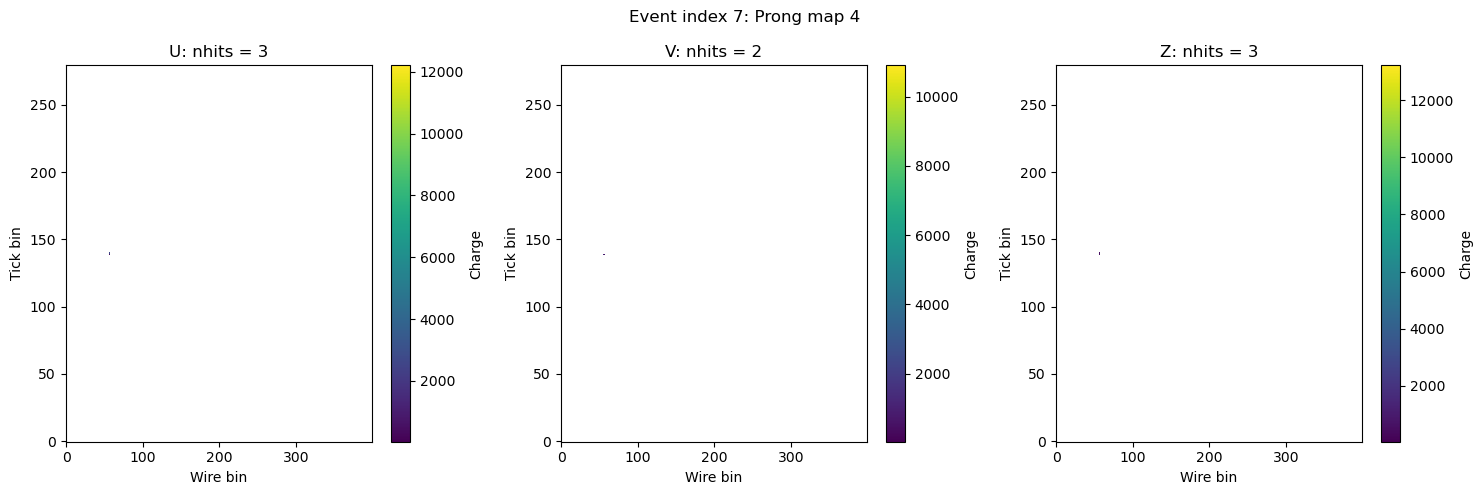

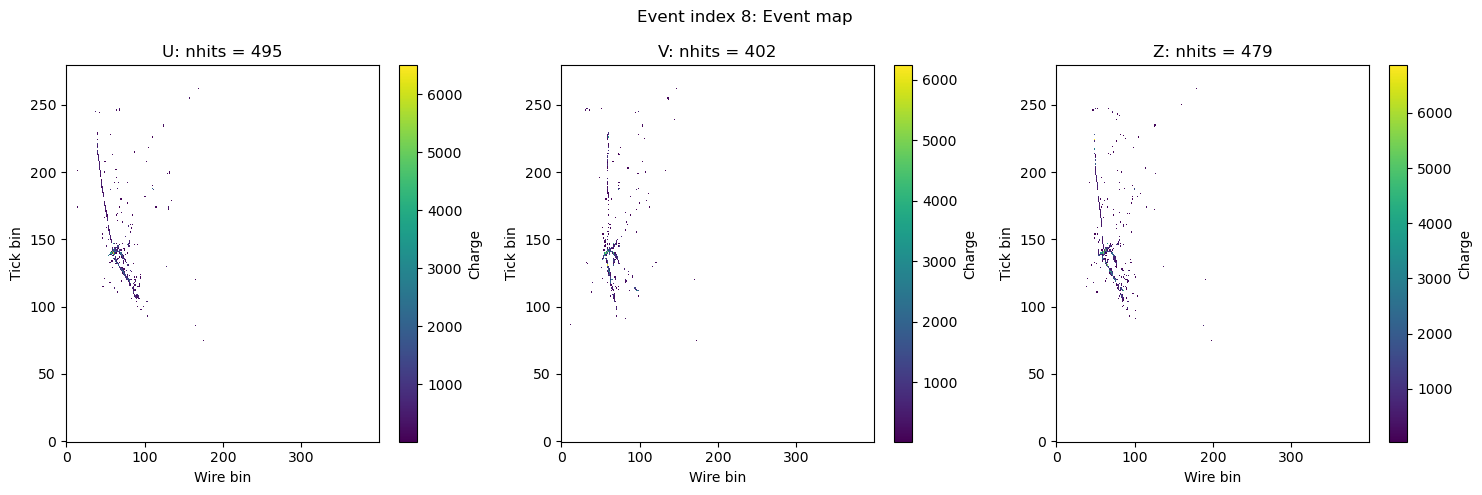

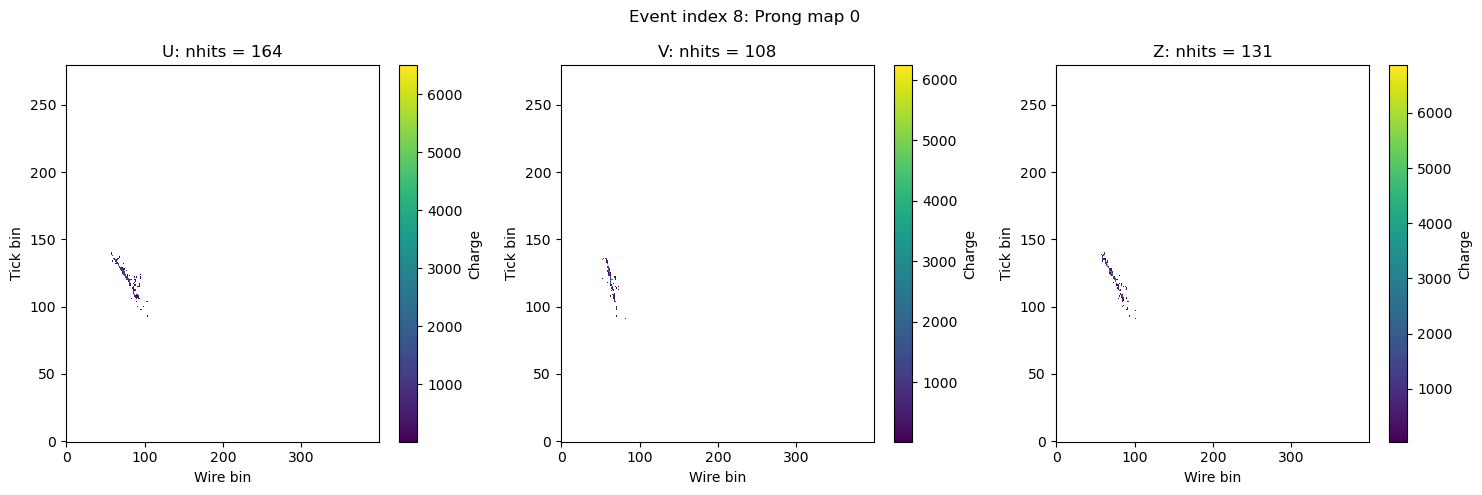

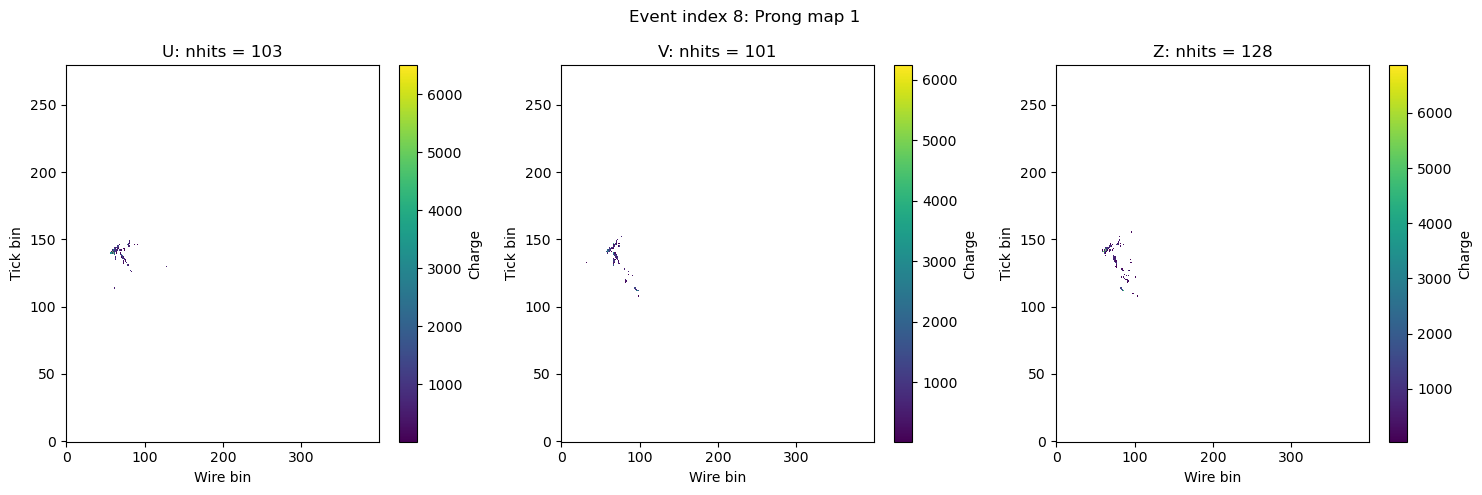

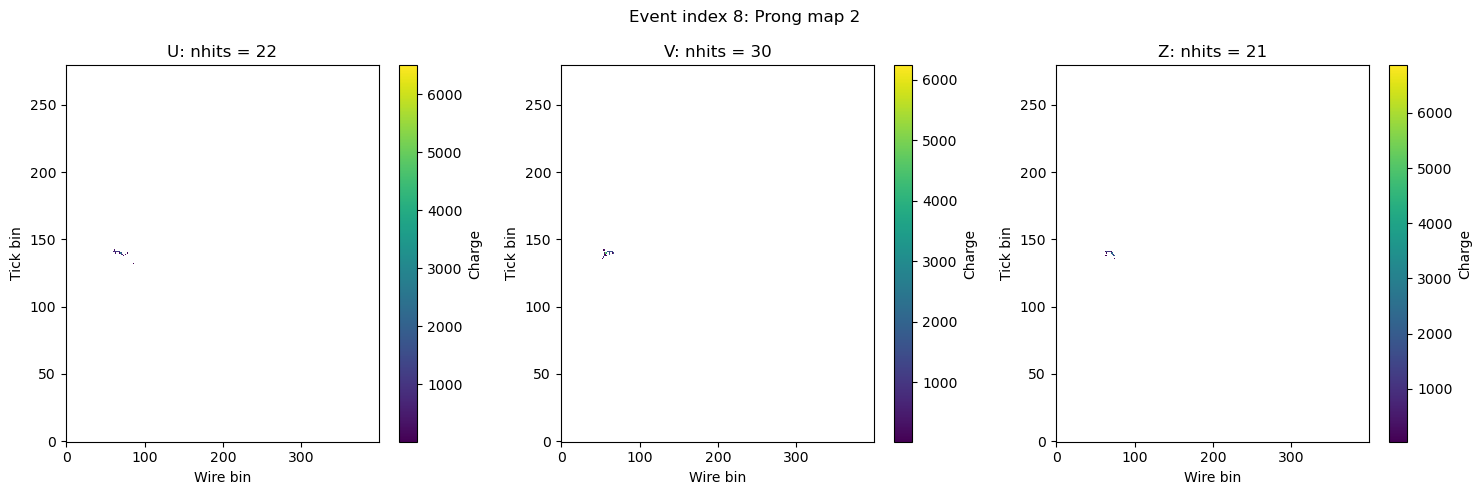

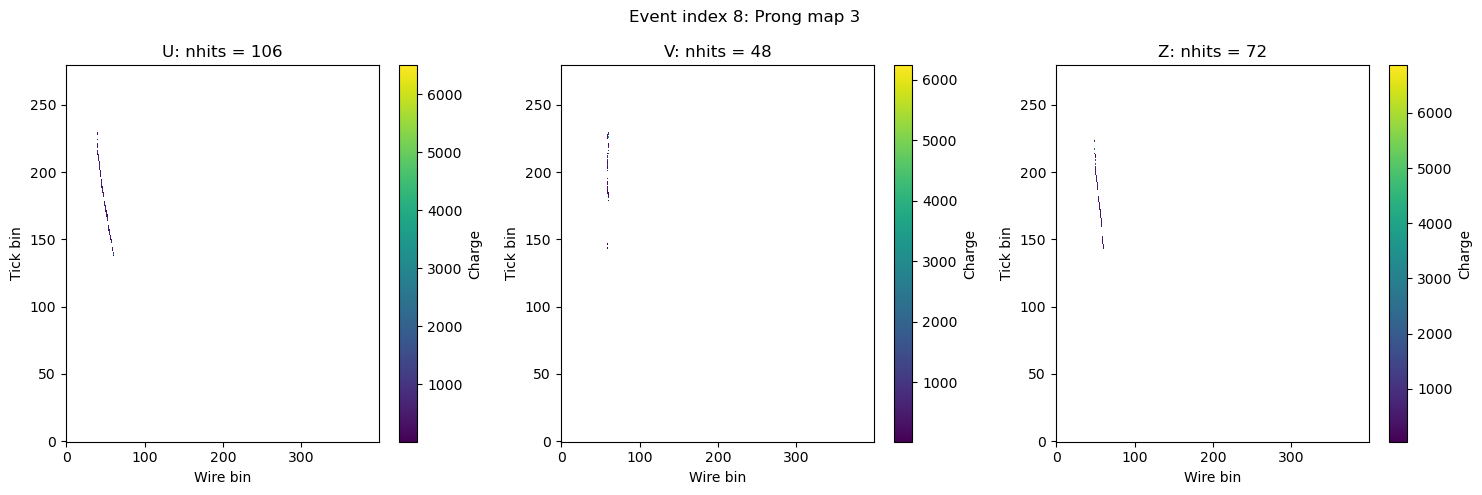

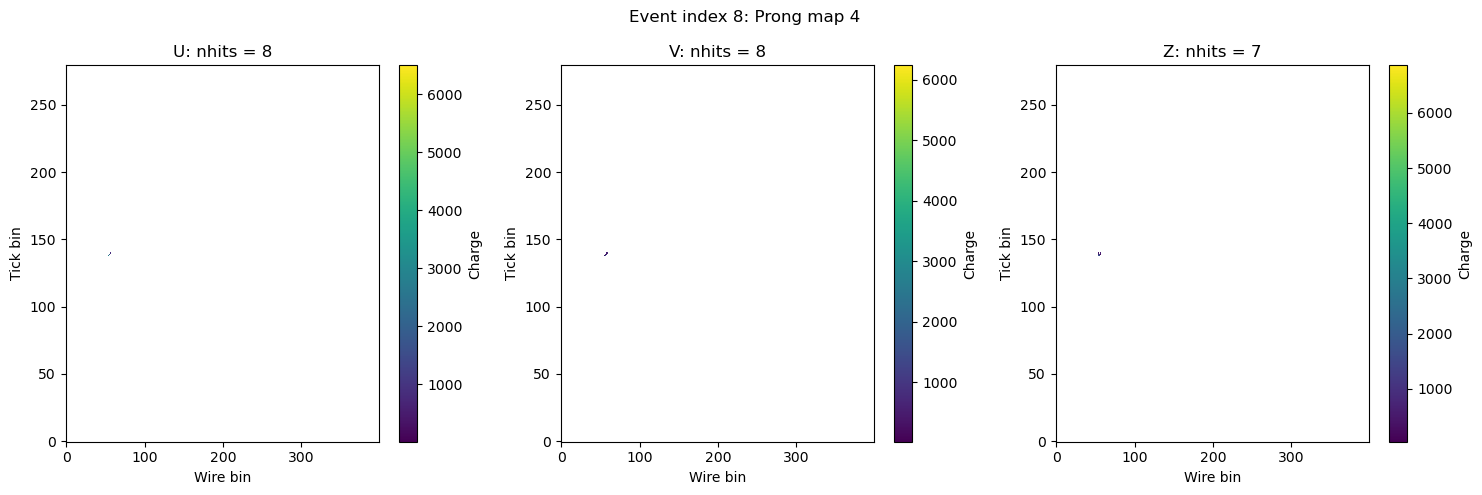

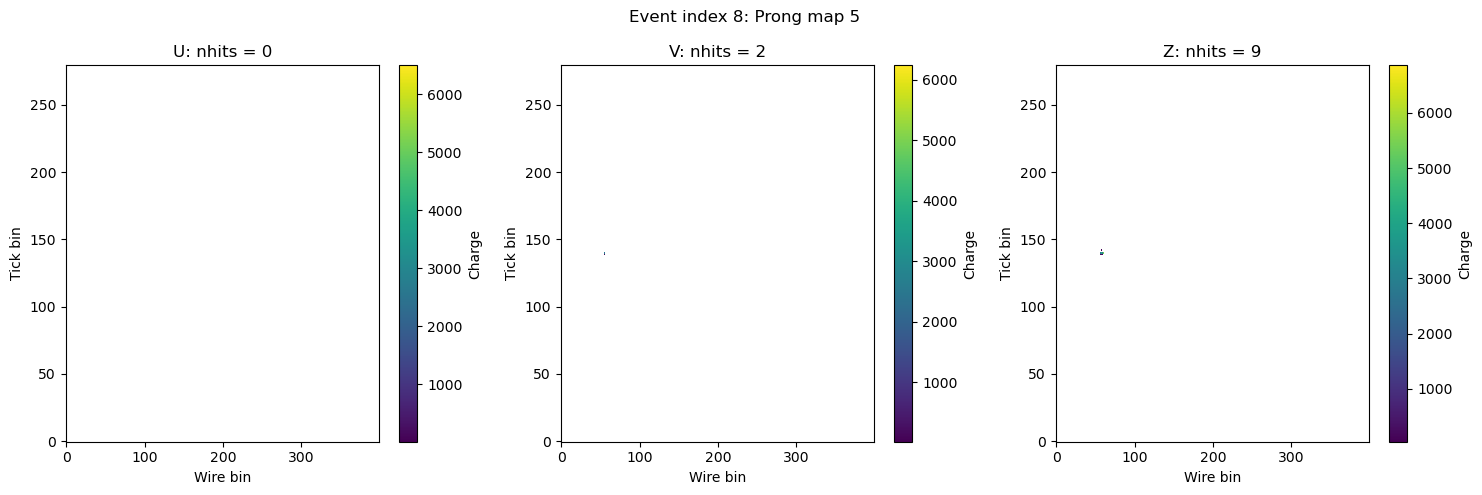

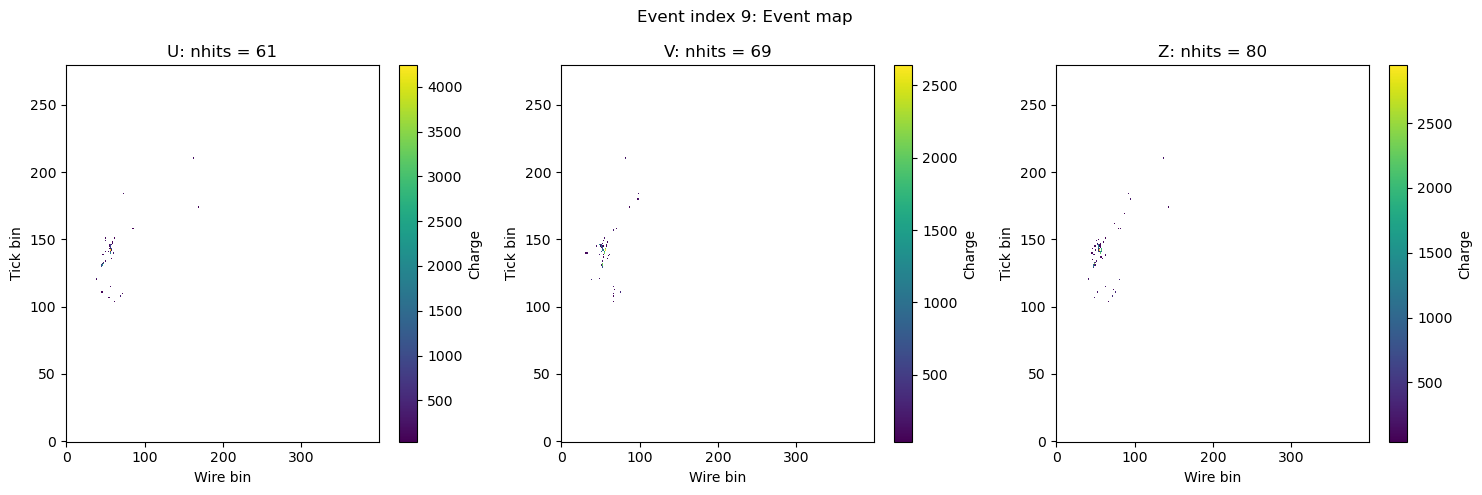

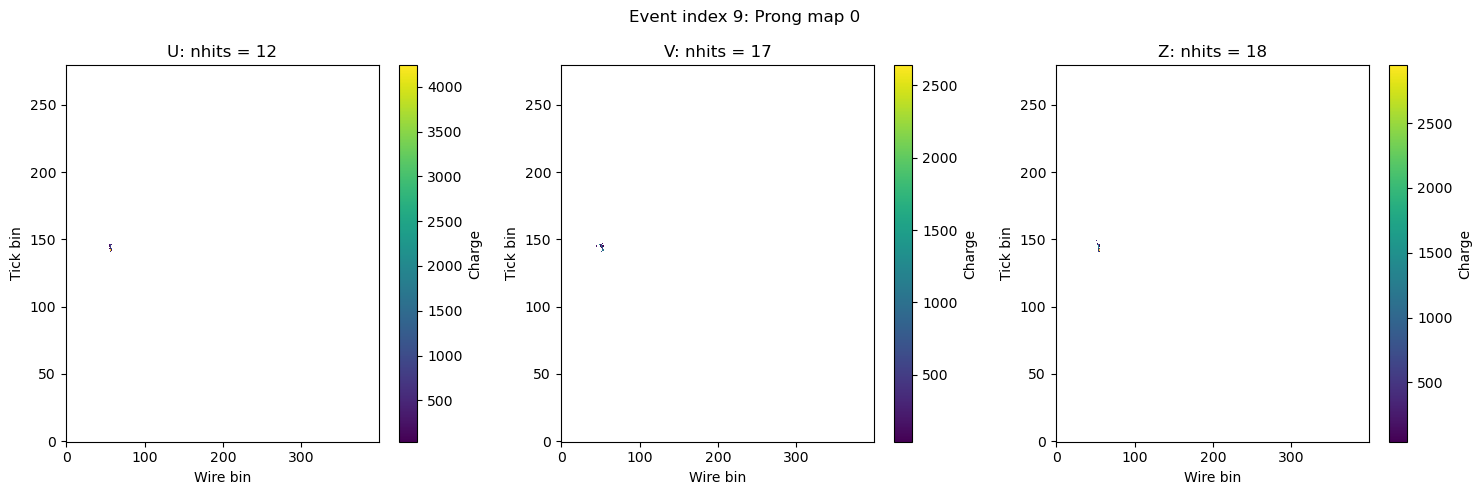

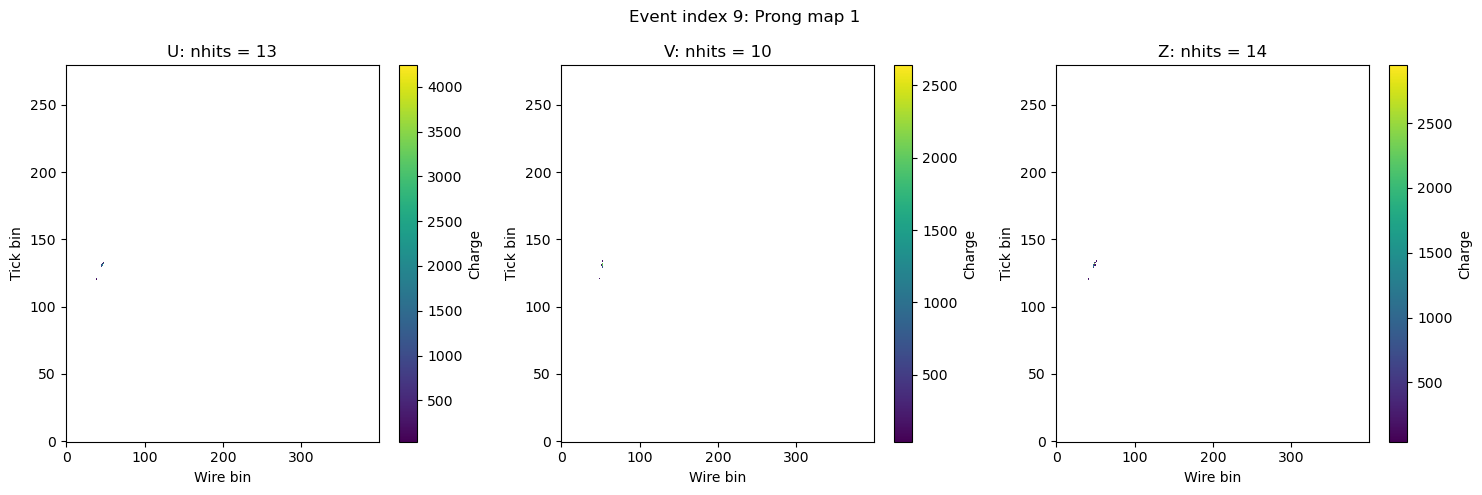

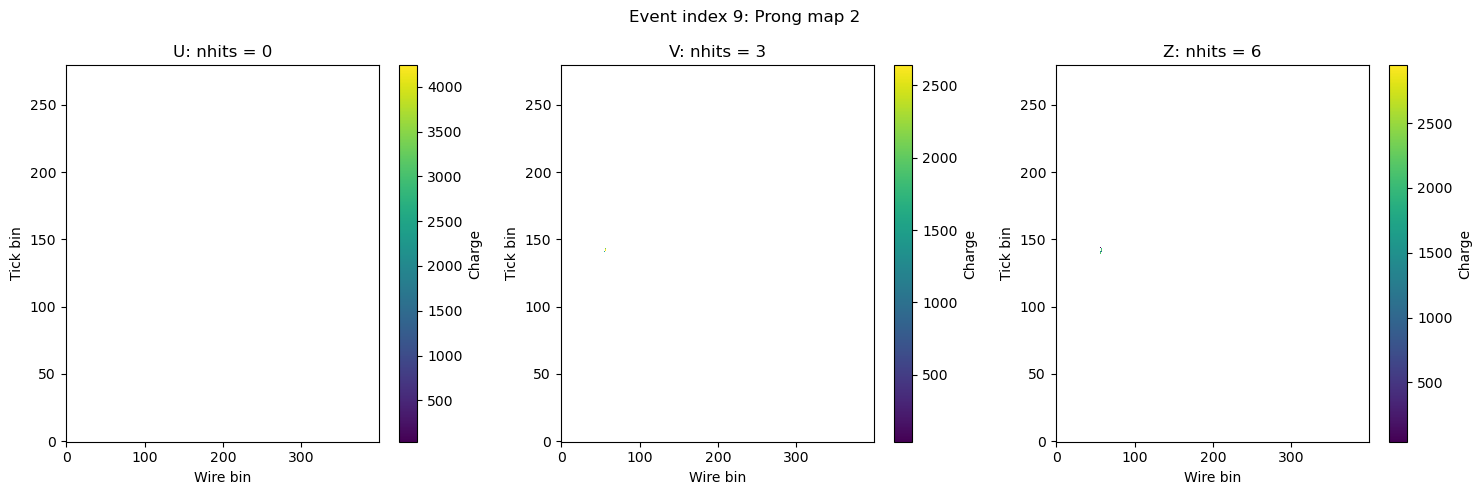

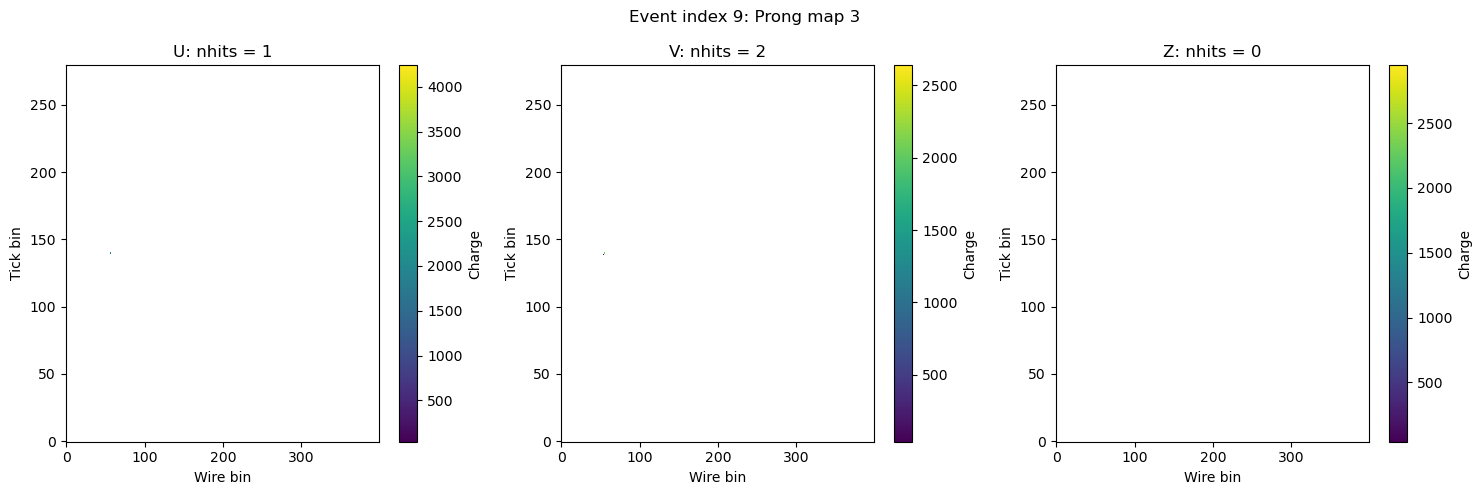

In [38]:
# Read the saved sparse maps and display ten events. IDX is zero-based.
import matplotlib.pyplot as plt

IDX = 0


def plot_pixel_maps(output_path, event_index):
    with h5py.File(output_path, "r") as saved:
        num_events = len(saved["event_target"])
        if not 0 <= event_index < num_events:
            raise ValueError(f"IDX must be between 0 and {num_events - 1}")

        for kind in ("event", "prong"):
            start, end = saved[f"{kind}_compressed_index"][event_index]
            coordinates = saved[f"{kind}_pixels_coordinates"][start:end]
            values = saved[f"{kind}_pixels_values"][start:end]
            shape = tuple(saved[f"{kind}_pixels_shape"][:])
            images = np.zeros(shape, dtype=np.float32)
            for plane in range(shape[1]):
                images[coordinates[:, 0], plane, coordinates[:, 1], coordinates[:, 2]] = values[:, plane]

            if kind == "event":
                # Reuse each event plane's color scale for all its prong maps.
                color_limits = []
                for pixels in images[0]:
                    nonzero = pixels[pixels != 0]
                    color_limits.append((float(nonzero.min()), float(nonzero.max())) if nonzero.size else (0.0, 1.0))

            map_indices = [0] if kind == "event" else np.flatnonzero(saved["prong_mask"][event_index])
            for map_index in map_indices:
                fig, axes = plt.subplots(1, 3, figsize=(15, 5))
                title = "Event map" if kind == "event" else f"Prong map {map_index}"
                fig.suptitle(f"Event index {event_index}: {title}")
                for plane, ax in enumerate(axes):
                    pixels = images[map_index, plane]
                    image = ax.imshow(np.ma.masked_equal(pixels.T, 0), origin="lower",
                                      interpolation="nearest", aspect="auto", cmap="viridis",
                                      vmin=color_limits[plane][0], vmax=color_limits[plane][1])
                    ax.set_title(f"{'UVZ'[plane]}: nhits = {np.count_nonzero(pixels)}")
                    ax.set_xlabel("Wire bin")
                    ax.set_ylabel("Tick bin")
                    fig.colorbar(image, ax=ax, label="Charge")
                fig.tight_layout()
                plt.show()


for event_index in range(IDX, IDX + 10):
    plot_pixel_maps(OUTPUT_FILE, event_index)
